In [102]:
#импорты по красоте
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

import numpy as np
import re
from sklearn.model_selection import GroupShuffleSplit
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
import math

import time

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score



In [103]:
BASE = Path("dataset")

df = pd.read_csv(BASE / "dataset.csv")
df

,cwe,case,label,target,path
0,cwe23,s03__CWE23_Relative_Path_Traversal__wchar_t_co...,bad,1,dataset/cwe23/ll/s03__CWE23_Relative_Path_Trav...
1,cwe23,s03__CWE23_Relative_Path_Traversal__wchar_t_co...,good,0,dataset/cwe23/ll/s03__CWE23_Relative_Path_Trav...
2,cwe23,s01__CWE23_Relative_Path_Traversal__char_conso...,bad,1,dataset/cwe23/ll/s01__CWE23_Relative_Path_Trav...
3,cwe23,s01__CWE23_Relative_Path_Traversal__char_conso...,good,0,dataset/cwe23/ll/s01__CWE23_Relative_Path_Trav...
4,cwe23,s01__CWE23_Relative_Path_Traversal__char_conne...,bad,1,dataset/cwe23/ll/s01__CWE23_Relative_Path_Trav...
...,...,...,...,...,...
4699,cwe134,s03__CWE134_Uncontrolled_Format_String__wchar_...,good,0,dataset/cwe134/ll/s03__CWE134_Uncontrolled_For...
4700,cwe134,s02__CWE134_Uncontrolled_Format_String__char_f...,bad,1,dataset/cwe134/ll/s02__CWE134_Uncontrolled_For...
4701,cwe134,s02__CWE134_Uncontrolled_Format_String__char_f...,good,0,dataset/cwe134/ll/s02__CWE134_Uncontrolled_For...
4702,cwe134,s03__CWE134_Uncontrolled_Format_String__char_l...,bad,1,dataset/cwe134/ll/s03__CWE134_Uncontrolled_For...


In [104]:
print("Размер:", df.shape)
print()
print(df["cwe"].value_counts())
print()
print(df["label"].value_counts())

Размер: (4704, 5)

cwe
cwe23     1568
cwe78     1568
cwe134    1568
Name: count, dtype: int64

label
bad     2352
good    2352
Name: count, dtype: int64


In [105]:
df["exists"] = df["path"].apply(lambda p: Path(p).exists())
df["exists"].value_counts()

exists
True    4704
Name: count, dtype: int64

In [106]:
sample_path = Path(df.iloc[0]["path"])
print(sample_path)

dataset/cwe23/ll/s03__CWE23_Relative_Path_Traversal__wchar_t_console_ofstream_11/bad.ll


## Собственно вот оно и представление !!!

In [107]:
text = sample_path.read_text()
print(text[:2000])

; ModuleID = 'data/C/testcases/CWE23_Relative_Path_Traversal/s03/CWE23_Relative_Path_Traversal__wchar_t_console_ofstream_11.cpp'
source_filename = "data/C/testcases/CWE23_Relative_Path_Traversal/s03/CWE23_Relative_Path_Traversal__wchar_t_console_ofstream_11.cpp"
target datalayout = "e-m:e-p270:32:32-p271:32:32-p272:64:64-i64:64-i128:128-f80:128-n8:16:32:64-S128"
target triple = "x86_64-pc-linux-gnu"

%"class.std::basic_ofstream" = type { %"class.std::basic_ostream.base", %"class.std::basic_filebuf", %"class.std::basic_ios" }
%"class.std::basic_ostream.base" = type { ptr }
%"class.std::basic_filebuf" = type { %"class.std::basic_streambuf", %union.pthread_mutex_t, %"class.std::__basic_file", i32, %struct.__mbstate_t, %struct.__mbstate_t, %struct.__mbstate_t, ptr, i64, i8, i8, i8, i8, ptr, ptr, i8, ptr, ptr, i64, ptr, ptr }
%"class.std::basic_streambuf" = type { ptr, ptr, ptr, ptr, ptr, ptr, ptr, %"class.std::locale" }
%"class.std::locale" = type { ptr }
%union.pthread_mutex_t = type { %s

## инструкции LLVM, которые считаю

In [108]:
OPCODES = [
    "alloca",
    "load",
    "store",
    "getelementptr",
    "call",
    "invoke",
    "br",
    "switch",
    "phi",
    "select",
    "icmp",
    "fcmp",
    "add",
    "sub",
    "mul",
    "udiv",
    "sdiv",
    "fdiv",
    "and",
    "or",
    "xor",
    "shl",
    "lshr",
    "ashr",
    "trunc",
    "zext",
    "sext",
    "ptrtoint",
    "inttoptr",
    "bitcast",
    "ret",
]

## функция, которая превращает один .ll в набор чисел:

In [109]:
def extract_llvm_stats(path):
    text = Path(path).read_text(errors="ignore") # дешевле просто игнорить пока случаи с траблами
    lines = text.splitlines()

    features = {} # словарь фичей

    # количество фунций с телом

    features["functions"] = sum(
        1 for line in lines
        if line.lstrip().startswith("define ")
    )

    # Очень простая оценка числа basic blocks:
    # метки вроде entry:, if.then:, if.end:
    features["basic_blocks"] = sum(
        1 for line in lines
        if re.match(r"^\s*[A-Za-z$._][A-Za-z0-9$._-]*:\s*(;.*)?$", line)
    )

    # Счётчики LLVM-инструкций
    for opcode in OPCODES:
        features[opcode] = 0

    total_instructions = 0

    for line in lines:
        line = line.strip()

        if not line:
            continue

        if line.startswith(";"):
            continue

        # Отбрасываем декларации, определения функций и служебные строки
        if line.startswith((
            "define ",
            "declare ",
            "source_filename",
            "target ",
            "attributes ",
            "!",
            "@"
        )):
            continue

        # У инструкции может быть результат:
        # %5 = load ...
        #
        # либо результата может не быть:
        # store ...
        # br ...
        # ret ...

        if "=" in line:
            instruction = line.split("=", 1)[1].strip()
        else:
            instruction = line

        if not instruction:
            continue

        opcode = instruction.split()[0]

        if opcode in OPCODES:
            features[opcode] += 1
            total_instructions += 1

    features["instructions"] = total_instructions

    return features

In [110]:
stats = extract_llvm_stats(sample_path)
stats

{'functions': 1,
 'basic_blocks': 0,
 'alloca': 6,
 'load': 18,
 'store': 12,
 'getelementptr': 10,
 'call': 9,
 'invoke': 2,
 'br': 11,
 'switch': 0,
 'phi': 0,
 'select': 0,
 'icmp': 5,
 'fcmp': 0,
 'add': 0,
 'sub': 4,
 'mul': 0,
 'udiv': 0,
 'sdiv': 0,
 'fdiv': 0,
 'and': 0,
 'or': 0,
 'xor': 0,
 'shl': 0,
 'lshr': 0,
 'ashr': 0,
 'trunc': 1,
 'zext': 0,
 'sext': 0,
 'ptrtoint': 0,
 'inttoptr': 0,
 'bitcast': 0,
 'ret': 1,
 'instructions': 79}

## Датасет полный с фичами

In [111]:
feature_rows = []

for i, row in df.iterrows():
    features = extract_llvm_stats(row["path"])
    feature_rows.append(features)

features_df = pd.DataFrame(feature_rows)

features_df.head()

,functions,basic_blocks,alloca,load,store,getelementptr,call,invoke,br,switch,...,lshr,ashr,trunc,zext,sext,ptrtoint,inttoptr,bitcast,ret,instructions
0,1,0,6,18,12,10,9,2,11,0,...,0,0,1,0,0,0,0,0,1,79
1,3,0,10,8,16,12,15,4,7,0,...,0,0,0,0,0,0,0,0,3,77
2,1,0,4,18,12,10,7,0,10,0,...,0,0,1,0,1,0,0,0,1,73
3,3,0,6,8,16,12,10,0,4,0,...,0,0,0,0,0,0,0,0,3,61
4,2,0,9,28,21,12,14,0,17,0,...,0,0,1,0,1,0,0,0,2,118


In [112]:
features_df.shape

(4704, 34)

In [113]:
data_stats = pd.concat(
    [
        df[["cwe", "case", "label", "target"]].reset_index(drop=True),
        features_df.reset_index(drop=True),
    ],
    axis=1,
)

data_stats

,cwe,case,label,target,functions,basic_blocks,alloca,load,store,getelementptr,...,lshr,ashr,trunc,zext,sext,ptrtoint,inttoptr,bitcast,ret,instructions
0,cwe23,s03__CWE23_Relative_Path_Traversal__wchar_t_co...,bad,1,1,0,6,18,12,10,...,0,0,1,0,0,0,0,0,1,79
1,cwe23,s03__CWE23_Relative_Path_Traversal__wchar_t_co...,good,0,3,0,10,8,16,12,...,0,0,0,0,0,0,0,0,3,77
2,cwe23,s01__CWE23_Relative_Path_Traversal__char_conso...,bad,1,1,0,4,18,12,10,...,0,0,1,0,1,0,0,0,1,73
3,cwe23,s01__CWE23_Relative_Path_Traversal__char_conso...,good,0,3,0,6,8,16,12,...,0,0,0,0,0,0,0,0,3,61
4,cwe23,s01__CWE23_Relative_Path_Traversal__char_conne...,bad,1,2,0,9,28,21,12,...,0,0,1,0,1,0,0,0,2,118
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4699,cwe134,s03__CWE134_Uncontrolled_Format_String__wchar_...,good,0,5,0,15,27,18,12,...,0,0,1,0,1,0,0,0,5,129
4700,cwe134,s02__CWE134_Uncontrolled_Format_String__char_f...,bad,1,1,0,4,11,4,3,...,0,0,1,0,0,0,0,0,1,42
4701,cwe134,s02__CWE134_Uncontrolled_Format_String__char_f...,good,0,5,0,12,26,10,8,...,0,0,2,0,0,0,0,0,5,109
4702,cwe134,s03__CWE134_Uncontrolled_Format_String__char_l...,bad,1,1,0,11,28,17,9,...,0,0,1,0,1,0,0,0,1,120


# разбиваем на X и y


In [114]:
FEAUTURE_COLUMNS = list(features_df.columns)

X = data_stats[FEAUTURE_COLUMNS]
y = data_stats["target"]

print(X.shape)
print(y.shape)

(4704, 34)
(4704,)


## Используем GroupShuffleSplit т.к. на классы можно разбить по разным меткам

In [115]:
groups = data_stats["cwe"] + "::" + data_stats["case"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=.2,
    random_state=42 #надеюсь, что бдует воспроизводимо
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Train", X_train.shape)

Train (3762, 34)


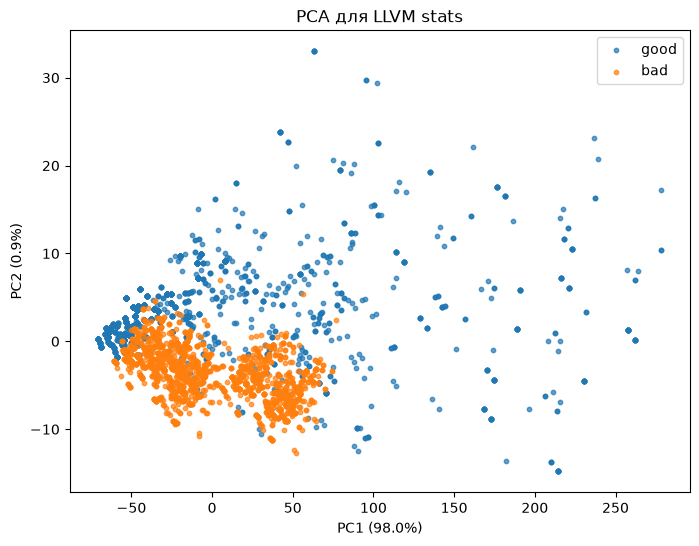

In [116]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train)

fig, ax = plt.subplots(figsize=(8, 6))

good = y_train == 0
bad = y_train == 1

ax.scatter(
    X_pca[good, 0],
    X_pca[good, 1],
    s=10,
    alpha=0.7,
    label="good"
)

ax.scatter(
    X_pca[bad, 0],
    X_pca[bad, 1],
    s=10,
    alpha=0.7,
    label="bad"
)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA для LLVM stats")
ax.legend()

plt.show()

## Логистическая регрессия

In [117]:


model = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("clf", LogisticRegression(
        C=1.0,
        max_iter=5000,
        random_state=42,
    )),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](34,)","['functions','basic_blocks','alloca',...,'bitcast','ret','instructions']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,34
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [118]:
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]

In [119]:

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_score))

Accuracy : 0.9787685774946921
Precision: 0.9870410367170627
Recall   : 0.970276008492569
F1       : 0.9785867237687366
ROC-AUC  : 0.9951046019446361


[[465   6]
 [ 14 457]]


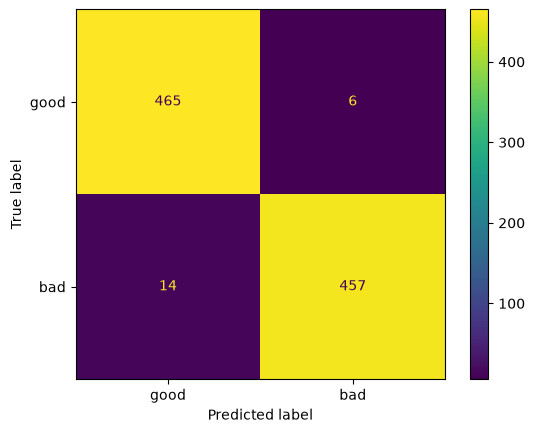

In [120]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["good", "bad"]
).plot()

In [121]:
tn, fp, fn, tp = cm.ravel()

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

True Negative : 465
False Positive: 6
False Negative: 14
True Positive : 457


## Теперь опкоды тф-идф

In [122]:
OPCODE_SET = set(OPCODES)

def extract_opcode_sequence(path):
    text = Path(path).read_text(errors="ignore")

    sequence = []

    for raw_line in text.splitlines():

        line = raw_line.strip()

        if not line:
            continue

        if line.startswith(";"):
            continue

        if line.startswith((
            "define ",
            "declare ",
            "source_filename",
            "target ",
            "attributes ",
            "!",
            "@"
        )):
            continue

        # Если инструкция сохраняет результат:
        # %8 = load ...
        # %9 = call ...
        if "=" in line:
            instruction = line.split("=", 1)[1].strip()
        else:
            instruction = line

        tokens = instruction.split()

        if not tokens:
            continue

        opcode = tokens[0]

        # На случай LLVM-вариантов:
        # tail call ...
        # musttail call ...
        if opcode in {"tail", "musttail", "notail"}:
            if len(tokens) > 1 and tokens[1] == "call":
                opcode = "call"

        if opcode in OPCODE_SET:
            sequence.append(opcode)

    return sequence

In [123]:
seq = extract_opcode_sequence(df.iloc[0]["path"])

print(seq[:50])
print()
print("Количество инструкций:", len(seq))

['alloca', 'alloca', 'alloca', 'alloca', 'alloca', 'alloca', 'call', 'getelementptr', 'store', 'getelementptr', 'store', 'getelementptr', 'store', 'getelementptr', 'store', 'getelementptr', 'store', 'getelementptr', 'store', 'call', 'icmp', 'br', 'load', 'call', 'store', 'load', 'sub', 'icmp', 'br', 'load', 'load', 'getelementptr', 'load', 'sub', 'trunc', 'load', 'call', 'icmp', 'br', 'load', 'call', 'store', 'load', 'icmp', 'br', 'load', 'load', 'sub', 'getelementptr', 'load']

Количество инструкций: 79


## текст для каждого из 4704 файлов:

In [124]:
opcode_texts = []

for path in df["path"]:
    seq = extract_opcode_sequence(path)
    opcode_texts.append(" ".join(seq))

print(opcode_texts[0][:500])

alloca alloca alloca alloca alloca alloca call getelementptr store getelementptr store getelementptr store getelementptr store getelementptr store getelementptr store call icmp br load call store load sub icmp br load load getelementptr load sub trunc load call icmp br load call store load icmp br load load sub getelementptr load icmp br load load sub getelementptr store br br call load load getelementptr store br br br call load invoke invoke call ret store store call br load load


In [125]:
train_texts = [opcode_texts[i] for i in train_idx]
test_texts = [opcode_texts[i] for i in test_idx]

y_train_tfidf = y.iloc[train_idx]
y_test_tfidf = y.iloc[test_idx]

 ngram_range=(1, 2) означает, что модель получает и отдельные инструкции:
- load
- call
- br

и пары соседних инструкций:

- load call
- call store
- icmp br

In [126]:


tfidf = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    ngram_range=(1, 2),
    min_df=2,
)

In [127]:
X_train_tfidf = tfidf.fit_transform(train_texts)
X_test_tfidf = tfidf.transform(test_texts)

print("Train:", X_train_tfidf.shape)
print("Test :", X_test_tfidf.shape)

Train: (3762, 74)
Test : (942, 74)


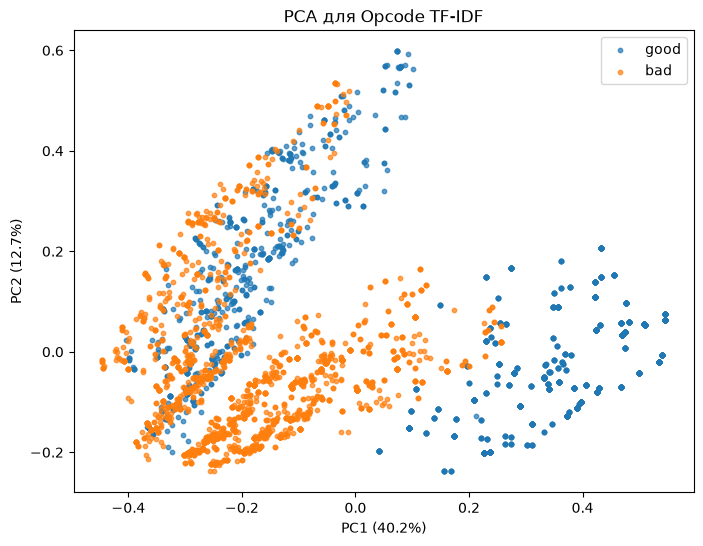

In [128]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_tfidf)

fig, ax = plt.subplots(figsize=(8, 6))

good = y_train == 0
bad = y_train == 1

ax.scatter(
    X_pca[good, 0],
    X_pca[good, 1],
    s=10,
    alpha=0.7,
    label="good"
)

ax.scatter(
    X_pca[bad, 0],
    X_pca[bad, 1],
    s=10,
    alpha=0.7,
    label="bad"
)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA для Opcode TF-IDF")
ax.legend()

plt.show()

# Вот здесь уже буквально видно, что представляют признаки модели.

In [129]:
feature_names = tfidf.get_feature_names_out()

print("Количество TF-IDF признаков:", len(feature_names))
print(feature_names[:50])

Количество TF-IDF признаков: 74
['add' 'add getelementptr' 'add store' 'alloca' 'alloca alloca'
 'alloca call' 'alloca load' 'alloca store' 'br' 'br br' 'br call'
 'br getelementptr' 'br load' 'br ret' 'br store' 'call' 'call br'
 'call call' 'call getelementptr' 'call icmp' 'call load' 'call ret'
 'call store' 'call trunc' 'getelementptr' 'getelementptr call'
 'getelementptr getelementptr' 'getelementptr load' 'getelementptr store'
 'icmp' 'icmp br' 'invoke' 'invoke call' 'invoke invoke' 'load' 'load add'
 'load alloca' 'load call' 'load getelementptr' 'load icmp' 'load invoke'
 'load load' 'load ret' 'load sext' 'load store' 'load sub' 'mul'
 'mul call' 'ret' 'ret alloca']


In [130]:
from sklearn.linear_model import LogisticRegression

tfidf_model = LogisticRegression(
    C=1.0,
    max_iter=5000,
    random_state=42,
)

tfidf_model.fit(
    X_train_tfidf,
    y_train_tfidf
)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [131]:
y_pred_tfidf = tfidf_model.predict(X_test_tfidf)

y_score_tfidf = tfidf_model.predict_proba(
    X_test_tfidf
)[:, 1]

In [132]:
print("Accuracy :", accuracy_score(y_test_tfidf, y_pred_tfidf))
print("Precision:", precision_score(y_test_tfidf, y_pred_tfidf))
print("Recall   :", recall_score(y_test_tfidf, y_pred_tfidf))
print("F1       :", f1_score(y_test_tfidf, y_pred_tfidf))
print("ROC-AUC  :", roc_auc_score(y_test_tfidf, y_score_tfidf))

Accuracy : 0.9766454352441614
Precision: 0.9648033126293996
Recall   : 0.9893842887473461
F1       : 0.9769392033542977
ROC-AUC  : 0.998413277978372


[[454  17]
 [  5 466]]


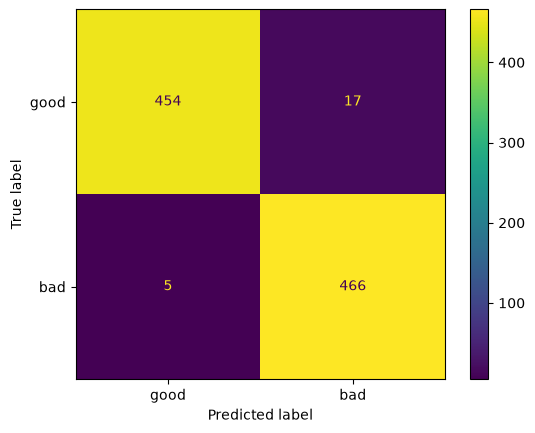

In [133]:
cm_tfidf = confusion_matrix(
    y_test_tfidf,
    y_pred_tfidf
)

print(cm_tfidf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tfidf,
    display_labels=["good", "bad"]
).plot()

In [134]:
results = pd.DataFrame([
    {
        "representation": "LLVM stats",
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_score),
    },
    {
        "representation": "Opcode TF-IDF",
        "accuracy": accuracy_score(y_test_tfidf, y_pred_tfidf),
        "precision": precision_score(y_test_tfidf, y_pred_tfidf),
        "recall": recall_score(y_test_tfidf, y_pred_tfidf),
        "f1": f1_score(y_test_tfidf, y_pred_tfidf),
        "roc_auc": roc_auc_score(y_test_tfidf, y_score_tfidf),
    }
])

results

,representation,accuracy,precision,recall,f1,roc_auc
0,LLVM stats,0.978769,0.987041,0.970276,0.978587,0.995105
1,Opcode TF-IDF,0.976645,0.964803,0.989384,0.976939,0.998413


## структурные признаки CFG.

In [135]:


def extract_cfg_features(path):
    text = Path(path).read_text(errors="ignore")
    lines = text.splitlines()

    functions = 0
    basic_blocks = 0
    edges = 0
    total_instructions = 0

    conditional_branches = 0
    unconditional_branches = 0
    switches = 0
    returns = 0

    inside_function = False

    for raw_line in lines:
        line = raw_line.strip()

        if line.startswith("define "):
            functions += 1
            inside_function = True
            continue

        if inside_function and line == "}":
            inside_function = False
            continue

        if not inside_function:
            continue

        if not line or line.startswith(";"):
            continue

        # Метка basic block:
        # entry:
        # 13:
        # if.then:
        if re.match(r"^[A-Za-z0-9$._-]+:\s*(;.*)?$", line):
            basic_blocks += 1
            continue

        # Убираем левую часть:
        # %12 = icmp ...
        if "=" in line:
            instruction = line.split("=", 1)[1].strip()
        else:
            instruction = line

        tokens = instruction.split()

        if not tokens:
            continue

        opcode = tokens[0]

        if opcode in OPCODE_SET:
            total_instructions += 1

        # conditional:
        # br i1 %cond, label %A, label %B
        if line.startswith("br i1 "):
            conditional_branches += 1
            edges += 2

        # unconditional:
        # br label %A
        elif line.startswith("br label "):
            unconditional_branches += 1
            edges += 1

        elif line.startswith("switch "):
            switches += 1

            # Каждый "label %" соответствует выходному ребру
            n_targets = len(re.findall(r"label\s+%", line))
            edges += n_targets

        elif line.startswith("ret "):
            returns += 1

    # В LLVM первый block функции иногда не имеет явной метки.
    # Поэтому как грубую структурную оценку добавляем по одному entry block
    # на функцию.
    nodes = basic_blocks + functions

    if nodes > 0:
        edges_per_node = edges / nodes
        instructions_per_block = total_instructions / nodes
    else:
        edges_per_node = 0.0
        instructions_per_block = 0.0

    if functions > 0:
        blocks_per_function = nodes / functions
    else:
        blocks_per_function = 0.0

    # Приближение цикломатической сложности:
    # M = E - N + 2P
    cyclomatic = edges - nodes + 2 * functions

    return {
        "functions": functions,
        "cfg_nodes": nodes,
        "cfg_edges": edges,
        "cyclomatic": cyclomatic,
        "instructions": total_instructions,
        "conditional_branches": conditional_branches,
        "unconditional_branches": unconditional_branches,
        "switches": switches,
        "returns": returns,
        "edges_per_node": edges_per_node,
        "instructions_per_block": instructions_per_block,
        "blocks_per_function": blocks_per_function,
    }

In [136]:
cfg_example = extract_cfg_features(df.iloc[0]["path"])

cfg_example

{'functions': 1,
 'cfg_nodes': 15,
 'cfg_edges': 16,
 'cyclomatic': 3,
 'instructions': 79,
 'conditional_branches': 5,
 'unconditional_branches': 6,
 'switches': 0,
 'returns': 1,
 'edges_per_node': 1.0666666666666667,
 'instructions_per_block': 5.266666666666667,
 'blocks_per_function': 15.0}

In [137]:
cfg_rows = []

for path in df["path"]:
    cfg_rows.append(
        extract_cfg_features(path)
    )

cfg_df = pd.DataFrame(cfg_rows)

cfg_df.head()

,functions,cfg_nodes,cfg_edges,cyclomatic,instructions,conditional_branches,unconditional_branches,switches,returns,edges_per_node,instructions_per_block,blocks_per_function
0,1,15,16,3,79,5,6,0,1,1.066667,5.266667,15.000000
1,3,16,9,-1,77,2,5,0,3,0.562500,4.812500,5.333333
2,1,11,15,6,73,5,5,0,1,1.363636,6.636364,11.000000
3,3,7,6,5,61,2,2,0,3,0.857143,8.714286,2.333333
4,2,19,25,10,118,8,9,0,2,1.315789,6.210526,9.500000


In [138]:
X_cfg = cfg_df
y_cfg = df["target"]

In [139]:
X_train_cfg = X_cfg.iloc[train_idx]
X_test_cfg = X_cfg.iloc[test_idx]

y_train_cfg = y_cfg.iloc[train_idx]
y_test_cfg = y_cfg.iloc[test_idx]

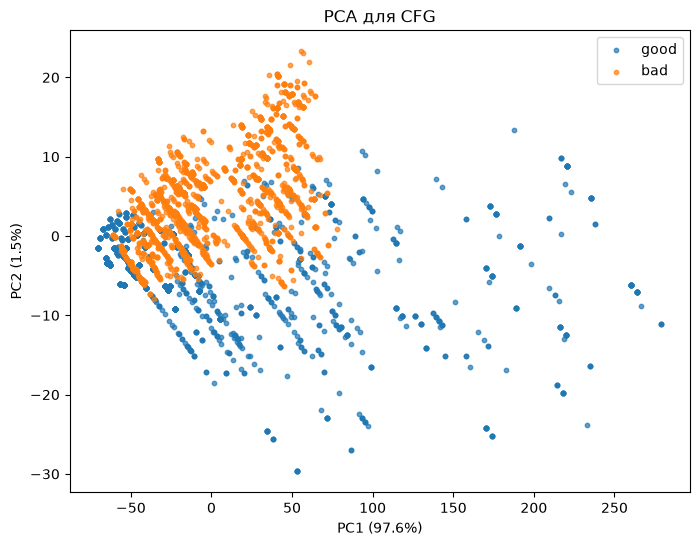

In [140]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_cfg)

fig, ax = plt.subplots(figsize=(8, 6))

good = y_train == 0
bad = y_train == 1

ax.scatter(
    X_pca[good, 0],
    X_pca[good, 1],
    s=10,
    alpha=0.7,
    label="good"
)

ax.scatter(
    X_pca[bad, 0],
    X_pca[bad, 1],
    s=10,
    alpha=0.7,
    label="bad"
)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA для CFG")
ax.legend()

plt.show()

In [141]:
cfg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        C=1.0,
        max_iter=5000,
        random_state=42,
    )),
])

cfg_model.fit(
    X_train_cfg,
    y_train_cfg
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['functions','cfg_nodes','cfg_edges',...,'edges_per_node', 'instructions_per_block','blocks_per_function']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [142]:
y_pred_cfg = cfg_model.predict(X_test_cfg)

y_score_cfg = cfg_model.predict_proba(
    X_test_cfg
)[:, 1]

In [143]:
print("Accuracy :", accuracy_score(y_test_cfg, y_pred_cfg))
print("Precision:", precision_score(y_test_cfg, y_pred_cfg))
print("Recall   :", recall_score(y_test_cfg, y_pred_cfg))
print("F1       :", f1_score(y_test_cfg, y_pred_cfg))
print("ROC-AUC  :", roc_auc_score(y_test_cfg, y_score_cfg))

Accuracy : 0.9692144373673036
Precision: 0.9804347826086957
Recall   : 0.9575371549893843
F1       : 0.9688506981740065
ROC-AUC  : 0.9954246509887713


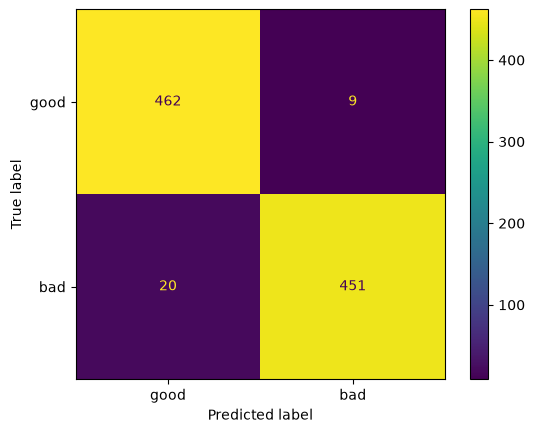

In [144]:
cm_cfg = confusion_matrix(
    y_test_cfg,
    y_pred_cfg
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_cfg,
    display_labels=["good", "bad"]
).plot()

In [145]:
results = pd.DataFrame([
    {
        "representation": "LLVM stats",
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_score),
    },
    {
        "representation": "Opcode TF-IDF",
        "accuracy": accuracy_score(y_test_tfidf, y_pred_tfidf),
        "precision": precision_score(y_test_tfidf, y_pred_tfidf),
        "recall": recall_score(y_test_tfidf, y_pred_tfidf),
        "f1": f1_score(y_test_tfidf, y_pred_tfidf),
        "roc_auc": roc_auc_score(y_test_tfidf, y_score_tfidf),
    },
    {
        "representation": "CFG structural",
        "accuracy": accuracy_score(y_test_cfg, y_pred_cfg),
        "precision": precision_score(y_test_cfg, y_pred_cfg),
        "recall": recall_score(y_test_cfg, y_pred_cfg),
        "f1": f1_score(y_test_cfg, y_pred_cfg),
        "roc_auc": roc_auc_score(y_test_cfg, y_score_cfg),
    },
])

results

,representation,accuracy,precision,recall,f1,roc_auc
0,LLVM stats,0.978769,0.987041,0.970276,0.978587,0.995105
1,Opcode TF-IDF,0.976645,0.964803,0.989384,0.976939,0.998413
2,CFG structural,0.969214,0.980435,0.957537,0.968851,0.995425


### Leave-One-CWE-Out

In [146]:
loo_stats_results = []

for held_out_cwe in ["cwe23", "cwe78", "cwe134"]:

    train_mask = df["cwe"] != held_out_cwe
    test_mask = df["cwe"] == held_out_cwe

    X_train_loo = features_df.loc[train_mask]
    X_test_loo = features_df.loc[test_mask]

    y_train_loo = df.loc[train_mask, "target"]
    y_test_loo = df.loc[test_mask, "target"]

    model_loo = Pipeline([
        ("scaler", StandardScaler(with_mean=False)),
        ("clf", LogisticRegression(
            C=1.0,
            max_iter=5000,
            random_state=42,
        )),
    ])

    model_loo.fit(X_train_loo, y_train_loo)

    y_pred_loo = model_loo.predict(X_test_loo)
    y_score_loo = model_loo.predict_proba(X_test_loo)[:, 1]

    loo_stats_results.append({
        "representation": "LLVM stats",
        "held_out_cwe": held_out_cwe,
        "accuracy": accuracy_score(y_test_loo, y_pred_loo),
        "precision": precision_score(y_test_loo, y_pred_loo),
        "recall": recall_score(y_test_loo, y_pred_loo),
        "f1": f1_score(y_test_loo, y_pred_loo),
        "roc_auc": roc_auc_score(y_test_loo, y_score_loo),
    })

loo_stats_df = pd.DataFrame(loo_stats_results)

loo_stats_df

,representation,held_out_cwe,accuracy,precision,recall,f1,roc_auc
0,LLVM stats,cwe23,0.981505,1.000000,0.96301,0.981157,0.996967
1,LLVM stats,cwe78,1.000000,1.000000,1.00000,1.000000,1.000000
2,LLVM stats,cwe134,0.601403,0.556423,1.00000,0.715002,0.606300


In [147]:
loo_cfg_results = []

for held_out_cwe in ["cwe23", "cwe78", "cwe134"]:

    train_mask = df["cwe"] != held_out_cwe
    test_mask = df["cwe"] == held_out_cwe

    X_train_loo = cfg_df.loc[train_mask]
    X_test_loo = cfg_df.loc[test_mask]

    y_train_loo = df.loc[train_mask, "target"]
    y_test_loo = df.loc[test_mask, "target"]

    model_loo = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            C=1.0,
            max_iter=5000,
            random_state=42,
        )),
    ])

    model_loo.fit(X_train_loo, y_train_loo)

    y_pred_loo = model_loo.predict(X_test_loo)
    y_score_loo = model_loo.predict_proba(X_test_loo)[:, 1]

    loo_cfg_results.append({
        "representation": "CFG structural",
        "held_out_cwe": held_out_cwe,
        "accuracy": accuracy_score(y_test_loo, y_pred_loo),
        "precision": precision_score(y_test_loo, y_pred_loo),
        "recall": recall_score(y_test_loo, y_pred_loo),
        "f1": f1_score(y_test_loo, y_pred_loo),
        "roc_auc": roc_auc_score(y_test_loo, y_score_loo),
    })

loo_cfg_df = pd.DataFrame(loo_cfg_results)

loo_cfg_df

,representation,held_out_cwe,accuracy,precision,recall,f1,roc_auc
0,CFG structural,cwe23,0.896684,0.919137,0.869898,0.893840,0.974181
1,CFG structural,cwe78,0.982781,0.966708,1.000000,0.983072,0.999597
2,CFG structural,cwe134,0.843750,0.817432,0.885204,0.849969,0.913802


In [148]:
loo_tfidf_results = []

for held_out_cwe in ["cwe23", "cwe78", "cwe134"]:

    train_mask = df["cwe"] != held_out_cwe
    test_mask = df["cwe"] == held_out_cwe

    train_indices = df.index[train_mask]
    test_indices = df.index[test_mask]

    train_texts = [opcode_texts[i] for i in train_indices]
    test_texts = [opcode_texts[i] for i in test_indices]

    y_train_loo = df.loc[train_mask, "target"]
    y_test_loo = df.loc[test_mask, "target"]

    tfidf_loo = TfidfVectorizer(
        tokenizer=str.split,
        preprocessor=None,
        token_pattern=None,
        ngram_range=(1, 2),
        min_df=2,
    )

    X_train_loo = tfidf_loo.fit_transform(train_texts)
    X_test_loo = tfidf_loo.transform(test_texts)

    model_loo = LogisticRegression(
        C=1.0,
        max_iter=5000,
        random_state=42,
    )

    model_loo.fit(X_train_loo, y_train_loo)

    y_pred_loo = model_loo.predict(X_test_loo)
    y_score_loo = model_loo.predict_proba(X_test_loo)[:, 1]

    loo_tfidf_results.append({
        "representation": "Opcode TF-IDF",
        "held_out_cwe": held_out_cwe,
        "accuracy": accuracy_score(y_test_loo, y_pred_loo),
        "precision": precision_score(y_test_loo, y_pred_loo),
        "recall": recall_score(y_test_loo, y_pred_loo),
        "f1": f1_score(y_test_loo, y_pred_loo),
        "roc_auc": roc_auc_score(y_test_loo, y_score_loo),
    })

loo_tfidf_df = pd.DataFrame(loo_tfidf_results)

loo_tfidf_df

,representation,held_out_cwe,accuracy,precision,recall,f1,roc_auc
0,Opcode TF-IDF,cwe23,1.000000,1.000000,1.000000,1.000000,1.000000
1,Opcode TF-IDF,cwe78,0.998087,1.000000,0.996173,0.998083,1.000000
2,Opcode TF-IDF,cwe134,0.515306,0.507772,1.000000,0.673540,0.905108


In [149]:
loo_results = pd.concat([
    loo_stats_df,
    loo_tfidf_df,
    loo_cfg_df,
], ignore_index=True)

loo_results

,representation,held_out_cwe,accuracy,precision,recall,f1,roc_auc
0,LLVM stats,cwe23,0.981505,1.000000,0.963010,0.981157,0.996967
1,LLVM stats,cwe78,1.000000,1.000000,1.000000,1.000000,1.000000
2,LLVM stats,cwe134,0.601403,0.556423,1.000000,0.715002,0.606300
3,Opcode TF-IDF,cwe23,1.000000,1.000000,1.000000,1.000000,1.000000
4,Opcode TF-IDF,cwe78,0.998087,1.000000,0.996173,0.998083,1.000000
5,Opcode TF-IDF,cwe134,0.515306,0.507772,1.000000,0.673540,0.905108
6,CFG structural,cwe23,0.896684,0.919137,0.869898,0.893840,0.974181
7,CFG structural,cwe78,0.982781,0.966708,1.000000,0.983072,0.999597
8,CFG structural,cwe134,0.843750,0.817432,0.885204,0.849969,0.913802


In [150]:
recall_table = loo_results.pivot(
    index="representation",
    columns="held_out_cwe",
    values="recall",
)

recall_table

held_out_cwe,cwe134,cwe23,cwe78
representation,,,
CFG structural,0.885204,0.869898,1.000000
LLVM stats,1.000000,0.963010,1.000000
Opcode TF-IDF,1.000000,1.000000,0.996173


## средний и худший Recall:

In [151]:
loo_summary = (
    loo_results
    .groupby("representation")
    .agg(
        mean_recall=("recall", "mean"),
        min_recall=("recall", "min"),
        mean_f1=("f1", "mean"),
        min_f1=("f1", "min"),
        mean_auc=("roc_auc", "mean"),
    )
    .sort_values("mean_recall", ascending=False)
)

loo_summary

,mean_recall,min_recall,mean_f1,min_f1,mean_auc
representation,,,,,
Opcode TF-IDF,0.998724,0.996173,0.890541,0.673540,0.968369
LLVM stats,0.987670,0.963010,0.898720,0.715002,0.867756
CFG structural,0.918367,0.869898,0.908961,0.849969,0.962527


То есть при стандартном пороге 0.5 модель почти всех объявляет bad. Поэтому Recall идеальный, но классификатор при таком пороге плоховат.

Но для нашей задачи это не обязательно проблема, потому что мы хотим не столько сказать:
bad / good

сколько получить:
насколько подозрителен объект?

То есть использовать y_score и сортировать объекты.

И здесь ROC-AUC у TF-IDF хороший, особенно в среднем:

Opcode TF-IDF:
mean Recall ≈ 0.999
worst Recall ≈ 0.996

mean AUC ≈ 0.968

Поэтому именно Opcode TF-IDF + Logistic Regression логично сейчас проверить как ранжировщик.

Делаем главный эксперимент: Recall vs доля выбранных объектов.

In [152]:
import math

fractions = [
    0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9, 1.0
]

ranking_rows = []
ranking_auc_rows = []

for held_out_cwe in ["cwe23", "cwe78", "cwe134"]:

    train_mask = df["cwe"] != held_out_cwe
    test_mask = df["cwe"] == held_out_cwe

    train_indices = df.index[train_mask]
    test_indices = df.index[test_mask]

    train_texts = [opcode_texts[i] for i in train_indices]
    test_texts = [opcode_texts[i] for i in test_indices]

    y_train_loo = df.loc[train_mask, "target"].to_numpy()
    y_test_loo = df.loc[test_mask, "target"].to_numpy()

    # TF-IDF обучаем только на train
    tfidf_loo = TfidfVectorizer(
        tokenizer=str.split,
        preprocessor=None,
        token_pattern=None,
        ngram_range=(1, 2),
        min_df=2,
    )

    X_train_loo = tfidf_loo.fit_transform(train_texts)
    X_test_loo = tfidf_loo.transform(test_texts)

    model_loo = LogisticRegression(
        C=1.0,
        max_iter=5000,
        random_state=42,
    )

    model_loo.fit(
        X_train_loo,
        y_train_loo
    )

    # Score: чем выше, тем сильнее модель считает объект bad
    scores = model_loo.predict_proba(
        X_test_loo
    )[:, 1]

    # ROC-AUC для полного held-out CWE
    auc = roc_auc_score(
        y_test_loo,
        scores
    )

    print(
        held_out_cwe,
        "ROC-AUC =",
        auc
    )

    ranking_auc_rows.append({
        "held_out_cwe": held_out_cwe,
        "roc_auc": auc,
    })

    # Сортируем от наиболее подозрительных к наименее
    order = np.argsort(-scores)

    y_sorted = y_test_loo[order]

    total_bad = y_test_loo.sum()

    for fraction in fractions:

        k = math.ceil(
            fraction * len(y_sorted)
        )

        selected = y_sorted[:k]

        found_bad = selected.sum()

        recall = found_bad / total_bad

        ranking_rows.append({
            "held_out_cwe": held_out_cwe,
            "fraction": fraction,
            "selected_objects": k,
            "found_bad": int(found_bad),
            "total_bad": int(total_bad),
            "recall": recall,
        })


# После завершения всех трёх LOO-экспериментов
ranking_df = pd.DataFrame(ranking_rows)

ranking_auc_df = pd.DataFrame(
    ranking_auc_rows
)

print()
print("ROC-AUC по CWE:")
display(ranking_auc_df)

print(
    "Mean ROC-AUC:",
    ranking_auc_df["roc_auc"].mean()
)

print(
    "Worst ROC-AUC:",
    ranking_auc_df["roc_auc"].min()
)

ranking_df

cwe23 ROC-AUC = 1.0
cwe78 ROC-AUC = 1.0
cwe134 ROC-AUC = 0.905107897750937

ROC-AUC по CWE:


,held_out_cwe,roc_auc
0,cwe23,1.000000
1,cwe78,1.000000
2,cwe134,0.905108


Mean ROC-AUC: 0.9683692992503122
Worst ROC-AUC: 0.905107897750937


,held_out_cwe,fraction,selected_objects,found_bad,total_bad,recall
0,cwe23,0.1,157,157,784,0.200255
1,cwe23,0.2,314,314,784,0.400510
2,cwe23,0.3,471,471,784,0.600765
3,cwe23,0.4,628,628,784,0.801020
4,cwe23,0.5,784,784,784,1.000000
5,cwe23,0.6,941,784,784,1.000000
6,cwe23,0.7,1098,784,784,1.000000
7,cwe23,0.8,1255,784,784,1.000000
8,cwe23,0.9,1412,784,784,1.000000
9,cwe23,1.0,1568,784,784,1.000000


In [153]:
recall_fraction_table = ranking_df.pivot(
    index="fraction",
    columns="held_out_cwe",
    values="recall",
)

recall_fraction_table

held_out_cwe,cwe134,cwe23,cwe78
fraction,,,
0.1,0.195153,0.200255,0.200255
0.2,0.353316,0.400510,0.400510
0.3,0.534439,0.600765,0.600765
0.4,0.723214,0.801020,0.801020
0.5,0.835459,1.000000,1.000000
0.6,0.924745,1.000000,1.000000
0.7,0.964286,1.000000,1.000000
0.8,0.988520,1.000000,1.000000
0.9,0.998724,1.000000,1.000000


средний и худший Recall на каждой доле

In [154]:
ranking_summary = (
    ranking_df
    .groupby("fraction")
    .agg(
        mean_recall=("recall", "mean"),
        worst_recall=("recall", "min"),
    )
    .reset_index()
)

ranking_summary

,fraction,mean_recall,worst_recall
0,0.1,0.198554,0.195153
1,0.2,0.384779,0.353316
2,0.3,0.578656,0.534439
3,0.4,0.775085,0.723214
4,0.5,0.945153,0.835459
5,0.6,0.974915,0.924745
6,0.7,0.988095,0.964286
7,0.8,0.996173,0.988520
8,0.9,0.999575,0.998724
9,1.0,1.000000,1.000000


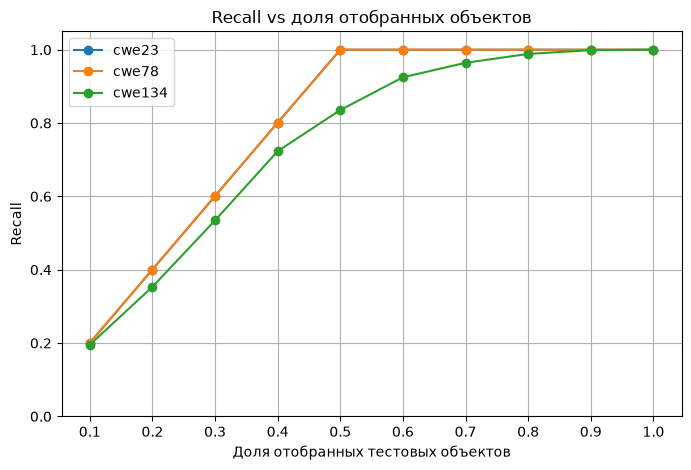

In [155]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for cwe in ["cwe23", "cwe78", "cwe134"]:
    part = ranking_df[
        ranking_df["held_out_cwe"] == cwe
    ]

    plt.plot(
        part["fraction"],
        part["recall"],
        marker="o",
        label=cwe,
    )

plt.xlabel("Доля отобранных тестовых объектов")
plt.ylabel("Recall")
plt.title("Recall vs доля отобранных объектов")
plt.xticks(fractions)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()

plt.show()

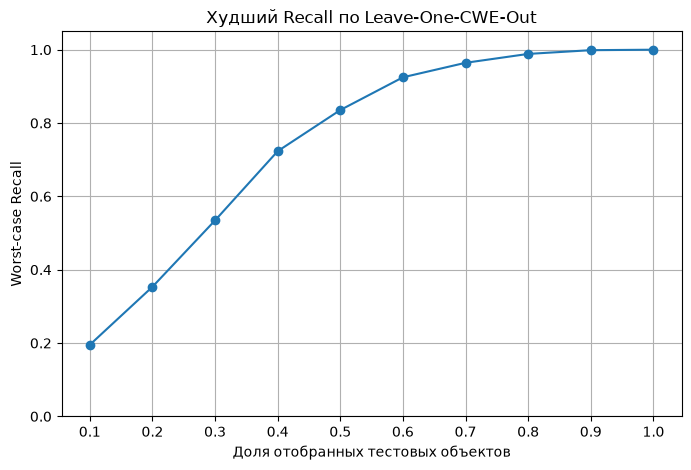

In [156]:
plt.figure(figsize=(8, 5))

plt.plot(
    ranking_summary["fraction"],
    ranking_summary["worst_recall"],
    marker="o",
)

plt.xlabel("Доля отобранных тестовых объектов")
plt.ylabel("Worst-case Recall")
plt.title("Худший Recall по Leave-One-CWE-Out")
plt.xticks(fractions)
plt.ylim(0, 1.05)
plt.grid(True)

plt.show()

In [157]:
for threshold in [0.90, 0.95, 0.99]:

    candidates = ranking_summary[
        ranking_summary["worst_recall"] >= threshold
    ]

    if len(candidates) == 0:
        print(
            f"Recall >= {threshold}: "
            "не достигнут"
        )
    else:
        first = candidates.iloc[0]

        print(
            f"Recall >= {threshold}: "
            f"{int(first['fraction'] * 100)}% объектов, "
            f"worst recall = {first['worst_recall']:.4f}"
        )

Recall >= 0.9: 60% объектов, worst recall = 0.9247
Recall >= 0.95: 70% объектов, worst recall = 0.9643
Recall >= 0.99: 90% объектов, worst recall = 0.9987


In [158]:
RESULTS_DIR = BASE / "results"
RESULTS_DIR.mkdir(exist_ok=True)

results.to_excel(
    RESULTS_DIR / "standard_split.xlsx",
    index=False,
)

loo_results.to_excel(
    RESULTS_DIR / "leave_one_cwe_out.xlsx",
    index=False,
)

ranking_df.to_excel(
    RESULTS_DIR / "ranking.xlsx",
    index=False,
)

ranking_summary.to_excel(
    RESULTS_DIR / "ranking_summary.xlsx",
    index=False,
)

ranking_auc_df.to_excel(
    RESULTS_DIR / "ranking_auc.xlsx",
    index=False,
)

print("Сохранено в:", RESULTS_DIR)

Сохранено в: dataset/results


In [159]:
def make_models():

    return {
        "LogReg": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("model", LogisticRegression(
                C=1.0,
                max_iter=5000,
                random_state=42,
            )),
        ]),

        "SVM": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("model", SVC(
                kernel="rbf",
                C=1.0,
                probability=True,
                random_state=42,
            )),
        ]),

        "XGBoost": XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            tree_method="hist",
            n_jobs=-1,
            random_state=42,
            eval_metric="logloss",
        ),

        "MLP": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("model", MLPClassifier(
                hidden_layer_sizes=(64, 32),
                max_iter=1000,
                early_stopping=True,
                random_state=42,
            )),
        ]),
    }

In [160]:
def evaluate_models(
    representation,
    X_train,
    X_test,
    y_train,
    y_test,
):

    rows = []

    models = make_models()

    for model_name, model in models.items():

        print(
            f"{representation} + {model_name}"
        )

        # Время обучения
        start = time.perf_counter()

        model.fit(
            X_train,
            y_train
        )

        train_time = time.perf_counter() - start

        # Время inference
        start = time.perf_counter()

        y_pred = model.predict(X_test)

        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(
                X_test
            )[:, 1]
        else:
            y_score = model.decision_function(
                X_test
            )

        inference_time = (
            time.perf_counter() - start
        )

        inference_us_per_sample = (
            inference_time
            / len(y_test)
            * 1_000_000
        )

        rows.append({
            "representation": representation,
            "model": model_name,

            "accuracy":
                accuracy_score(y_test, y_pred),

            "precision":
                precision_score(y_test, y_pred),

            "recall":
                recall_score(y_test, y_pred),

            "f1":
                f1_score(y_test, y_pred),

            "roc_auc":
                roc_auc_score(y_test, y_score),

            "train_time_s":
                train_time,

            "inference_us_per_sample":
                inference_us_per_sample,
        })

    return rows

In [161]:
X_stats = features_df

X_train_stats = X_stats.iloc[train_idx]
X_test_stats = X_stats.iloc[test_idx]

y_train_common = df["target"].iloc[train_idx]
y_test_common = df["target"].iloc[test_idx]

In [162]:
X_cfg = cfg_df

X_train_cfg = X_cfg.iloc[train_idx]
X_test_cfg = X_cfg.iloc[test_idx]

In [163]:
train_texts = [
    opcode_texts[i]
    for i in train_idx
]

test_texts = [
    opcode_texts[i]
    for i in test_idx
]

tfidf_standard = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    ngram_range=(1, 2),
    min_df=2,
)

X_train_tfidf = (
    tfidf_standard.fit_transform(
        train_texts
    )
)

X_test_tfidf = (
    tfidf_standard.transform(
        test_texts
    )
)

print(
    X_train_tfidf.shape,
    X_test_tfidf.shape
)

(3762, 74) (942, 74)


In [164]:
all_results = []

all_results += evaluate_models(
    "LLVM stats",
    X_train_stats,
    X_test_stats,
    y_train_common,
    y_test_common,
)

all_results += evaluate_models(
    "Opcode TF-IDF",
    X_train_tfidf,
    X_test_tfidf,
    y_train_common,
    y_test_common,
)

all_results += evaluate_models(
    "CFG structural",
    X_train_cfg,
    X_test_cfg,
    y_train_common,
    y_test_common,
)

LLVM stats + LogReg
LLVM stats + SVM
LLVM stats + XGBoost


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


LLVM stats + MLP
Opcode TF-IDF + LogReg
Opcode TF-IDF + SVM


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Opcode TF-IDF + XGBoost
Opcode TF-IDF + MLP
CFG structural + LogReg
CFG structural + SVM


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


CFG structural + XGBoost
CFG structural + MLP


In [165]:
benchmark_df = pd.DataFrame(
    all_results
)

benchmark_df

,representation,model,accuracy,precision,recall,f1,roc_auc,train_time_s,inference_us_per_sample
0,LLVM stats,LogReg,0.978769,0.987041,0.970276,0.978587,0.995105,0.007747,1.245610
1,LLVM stats,SVM,0.992569,0.989451,0.995754,0.992593,0.999910,0.126762,15.713640
2,LLVM stats,XGBoost,0.997877,1.000000,0.995754,0.997872,1.000000,0.124029,3.966329
3,LLVM stats,MLP,0.983015,0.995643,0.970276,0.982796,0.999675,0.144265,1.717184
4,Opcode TF-IDF,LogReg,1.000000,1.000000,1.000000,1.000000,1.000000,0.010487,0.599530
5,Opcode TF-IDF,SVM,0.992569,0.993617,0.991507,0.992561,0.999869,0.448945,39.002348
6,Opcode TF-IDF,XGBoost,0.998938,1.000000,0.997877,0.998937,1.000000,0.770966,1.363709
7,Opcode TF-IDF,MLP,0.995754,0.993658,0.997877,0.995763,0.999923,0.146022,1.509725
8,CFG structural,LogReg,0.970276,0.982571,0.957537,0.969892,0.995407,0.007733,1.161983
9,CFG structural,SVM,0.967091,0.982456,0.951168,0.966559,0.994591,0.184723,17.515122


In [166]:
benchmark_sorted = (
    benchmark_df
    .sort_values(
        ["recall", "f1", "roc_auc"],
        ascending=False,
    )
    .reset_index(drop=True)
)

benchmark_sorted

,representation,model,accuracy,precision,recall,f1,roc_auc,train_time_s,inference_us_per_sample
0,Opcode TF-IDF,LogReg,1.000000,1.000000,1.000000,1.000000,1.000000,0.010487,0.599530
1,Opcode TF-IDF,XGBoost,0.998938,1.000000,0.997877,0.998937,1.000000,0.770966,1.363709
2,Opcode TF-IDF,MLP,0.995754,0.993658,0.997877,0.995763,0.999923,0.146022,1.509725
3,LLVM stats,XGBoost,0.997877,1.000000,0.995754,0.997872,1.000000,0.124029,3.966329
4,LLVM stats,SVM,0.992569,0.989451,0.995754,0.992593,0.999910,0.126762,15.713640
5,CFG structural,XGBoost,0.995754,0.997868,0.993631,0.995745,0.999824,0.190599,5.470247
6,Opcode TF-IDF,SVM,0.992569,0.993617,0.991507,0.992561,0.999869,0.448945,39.002348
7,LLVM stats,MLP,0.983015,0.995643,0.970276,0.982796,0.999675,0.144265,1.717184
8,LLVM stats,LogReg,0.978769,0.987041,0.970276,0.978587,0.995105,0.007747,1.245610
9,CFG structural,LogReg,0.970276,0.982571,0.957537,0.969892,0.995407,0.007733,1.161983


In [167]:
standard_recall_table = (
    benchmark_df.pivot(
        index="representation",
        columns="model",
        values="recall",
    )
)

standard_recall_table

model,LogReg,MLP,SVM,XGBoost
representation,,,,
CFG structural,0.957537,0.957537,0.951168,0.993631
LLVM stats,0.970276,0.970276,0.995754,0.995754
Opcode TF-IDF,1.000000,0.997877,0.991507,0.997877


In [168]:
standard_f1_table = (
    benchmark_df.pivot(
        index="representation",
        columns="model",
        values="f1",
    )
)

standard_f1_table

model,LogReg,MLP,SVM,XGBoost
representation,,,,
CFG structural,0.969892,0.963675,0.966559,0.995745
LLVM stats,0.978587,0.982796,0.992593,0.997872
Opcode TF-IDF,1.000000,0.995763,0.992561,0.998937


In [169]:
standard_auc_table = (
    benchmark_df.pivot(
        index="representation",
        columns="model",
        values="roc_auc",
    )
)

standard_auc_table

model,LogReg,MLP,SVM,XGBoost
representation,,,,
CFG structural,0.995407,0.994244,0.994591,0.999824
LLVM stats,0.995105,0.999675,0.999910,1.000000
Opcode TF-IDF,1.000000,0.999923,0.999869,1.000000


## все 3 представления × 4 модели × 3 held-out CWE = 36 запусков

In [170]:
def evaluate_numeric_loo(
    representation,
    X,
):

    rows = []

    for held_out_cwe in ["cwe23", "cwe78", "cwe134"]:

        print(
            f"\n{representation} | "
            f"TEST = {held_out_cwe}"
        )

        train_mask = df["cwe"] != held_out_cwe
        test_mask = df["cwe"] == held_out_cwe

        X_train = X.loc[train_mask]
        X_test = X.loc[test_mask]

        y_train = df.loc[
            train_mask,
            "target"
        ]

        y_test = df.loc[
            test_mask,
            "target"
        ]

        models = make_models()

        for model_name, model in models.items():

            print("  ", model_name)

            start = time.perf_counter()

            model.fit(
                X_train,
                y_train
            )

            train_time = (
                time.perf_counter()
                - start
            )

            start = time.perf_counter()

            y_pred = model.predict(
                X_test
            )

            if hasattr(model, "predict_proba"):

                y_score = model.predict_proba(
                    X_test
                )[:, 1]

            else:

                y_score = model.decision_function(
                    X_test
                )

            inference_time = (
                time.perf_counter()
                - start
            )

            rows.append({

                "representation":
                    representation,

                "model":
                    model_name,

                "held_out_cwe":
                    held_out_cwe,

                "accuracy":
                    accuracy_score(
                        y_test,
                        y_pred
                    ),

                "precision":
                    precision_score(
                        y_test,
                        y_pred,
                        zero_division=0
                    ),

                "recall":
                    recall_score(
                        y_test,
                        y_pred
                    ),

                "f1":
                    f1_score(
                        y_test,
                        y_pred
                    ),

                "roc_auc":
                    roc_auc_score(
                        y_test,
                        y_score
                    ),

                "train_time_s":
                    train_time,

                "inference_us_per_sample":
                    (
                        inference_time
                        / len(y_test)
                        * 1_000_000
                    ),
            })

    return rows

In [171]:
def evaluate_tfidf_loo():

    rows = []

    for held_out_cwe in ["cwe23", "cwe78", "cwe134"]:

        print(
            f"\nOpcode TF-IDF | "
            f"TEST = {held_out_cwe}"
        )

        train_mask = df["cwe"] != held_out_cwe
        test_mask = df["cwe"] == held_out_cwe

        train_indices = df.index[
            train_mask
        ]

        test_indices = df.index[
            test_mask
        ]

        train_texts = [
            opcode_texts[i]
            for i in train_indices
        ]

        test_texts = [
            opcode_texts[i]
            for i in test_indices
        ]

        y_train = df.loc[
            train_mask,
            "target"
        ]

        y_test = df.loc[
            test_mask,
            "target"
        ]

        # Очень важно:
        # fit только на train
        tfidf = TfidfVectorizer(
            tokenizer=str.split,
            preprocessor=None,
            token_pattern=None,
            ngram_range=(1, 2),
            min_df=2,
        )

        X_train = tfidf.fit_transform(
            train_texts
        )

        X_test = tfidf.transform(
            test_texts
        )

        models = make_models()

        for model_name, model in models.items():

            print("  ", model_name)

            start = time.perf_counter()

            model.fit(
                X_train,
                y_train
            )

            train_time = (
                time.perf_counter()
                - start
            )

            start = time.perf_counter()

            y_pred = model.predict(
                X_test
            )

            if hasattr(model, "predict_proba"):

                y_score = model.predict_proba(
                    X_test
                )[:, 1]

            else:

                y_score = model.decision_function(
                    X_test
                )

            inference_time = (
                time.perf_counter()
                - start
            )

            rows.append({

                "representation":
                    "Opcode TF-IDF",

                "model":
                    model_name,

                "held_out_cwe":
                    held_out_cwe,

                "accuracy":
                    accuracy_score(
                        y_test,
                        y_pred
                    ),

                "precision":
                    precision_score(
                        y_test,
                        y_pred,
                        zero_division=0
                    ),

                "recall":
                    recall_score(
                        y_test,
                        y_pred
                    ),

                "f1":
                    f1_score(
                        y_test,
                        y_pred
                    ),

                "roc_auc":
                    roc_auc_score(
                        y_test,
                        y_score
                    ),

                "train_time_s":
                    train_time,

                "inference_us_per_sample":
                    (
                        inference_time
                        / len(y_test)
                        * 1_000_000
                    ),
            })

    return rows

In [172]:
loo_all_rows = []

loo_all_rows += evaluate_numeric_loo(
    "LLVM stats",
    features_df,
)

loo_all_rows += evaluate_tfidf_loo()

loo_all_rows += evaluate_numeric_loo(
    "CFG structural",
    cfg_df,
)


LLVM stats | TEST = cwe23
   LogReg
   SVM


   XGBoost


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   MLP

LLVM stats | TEST = cwe78
   LogReg
   SVM
   XGBoost


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   MLP

LLVM stats | TEST = cwe134
   LogReg
   SVM
   XGBoost


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   MLP

Opcode TF-IDF | TEST = cwe23
   LogReg
   SVM


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   XGBoost
   MLP

Opcode TF-IDF | TEST = cwe78
   LogReg
   SVM


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   XGBoost
   MLP

Opcode TF-IDF | TEST = cwe134
   LogReg
   SVM


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   XGBoost
   MLP

CFG structural | TEST = cwe23
   LogReg
   SVM
   XGBoost


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   MLP

CFG structural | TEST = cwe78
   LogReg
   SVM


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   XGBoost
   MLP

CFG structural | TEST = cwe134
   LogReg
   SVM
   XGBoost


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   MLP


In [173]:
loo_all_df = pd.DataFrame(
    loo_all_rows
)

loo_all_df

,representation,model,held_out_cwe,accuracy,precision,recall,f1,roc_auc,train_time_s,inference_us_per_sample
0,LLVM stats,LogReg,cwe23,0.981505,1.000000,0.963010,0.981157,0.996967,0.005947,0.684188
1,LLVM stats,SVM,cwe23,0.979592,1.000000,0.959184,0.979167,1.000000,0.103001,15.471100
2,LLVM stats,XGBoost,cwe23,0.998724,1.000000,0.997449,0.998723,1.000000,0.111420,2.471327
3,LLVM stats,MLP,cwe23,0.987245,1.000000,0.974490,0.987080,1.000000,0.185857,1.062620
4,LLVM stats,LogReg,cwe78,1.000000,1.000000,1.000000,1.000000,1.000000,0.010522,0.793807
5,LLVM stats,SVM,cwe78,1.000000,1.000000,1.000000,1.000000,1.000000,0.141560,16.652392
6,LLVM stats,XGBoost,cwe78,1.000000,1.000000,1.000000,1.000000,1.000000,0.187249,2.482611
7,LLVM stats,MLP,cwe78,1.000000,1.000000,1.000000,1.000000,1.000000,0.113933,1.176494
8,LLVM stats,LogReg,cwe134,0.601403,0.556423,1.000000,0.715002,0.606300,0.004995,0.763987
9,LLVM stats,SVM,cwe134,0.661990,0.596651,1.000000,0.747378,0.957931,0.052356,5.104501


In [174]:
loo_recall_matrix = loo_all_df.pivot_table(
    index=[
        "representation",
        "model"
    ],
    columns="held_out_cwe",
    values="recall",
)

loo_recall_matrix

held_out_cwe              cwe134     cwe23     cwe78
representation model                                
CFG structural LogReg   0.885204  0.869898  1.000000
               MLP      0.887755  0.946429  0.983418
               SVM      0.875000  0.941327  1.000000
               XGBoost  0.914541  0.969388  1.000000
LLVM stats     LogReg   1.000000  0.963010  1.000000
               MLP      0.984694  0.974490  1.000000
               SVM      1.000000  0.959184  1.000000
               XGBoost  1.000000  0.997449  1.000000
Opcode TF-IDF  LogReg   1.000000  1.000000  0.992347
               MLP      1.000000  0.994898  0.994898
               SVM      0.998724  1.000000  0.996173
               XGBoost  1.000000  1.000000  0.785714

In [175]:
loo_model_summary = (
    loo_all_df
    .groupby([
        "representation",
        "model"
    ])
    .agg(
        mean_recall=(
            "recall",
            "mean"
        ),
        min_recall=(
            "recall",
            "min"
        ),
        mean_f1=(
            "f1",
            "mean"
        ),
        min_f1=(
            "f1",
            "min"
        ),
        mean_auc=(
            "roc_auc",
            "mean"
        ),
        min_auc=(
            "roc_auc",
            "min"
        ),
        mean_train_time_s=(
            "train_time_s",
            "mean"
        ),
        mean_inference_us=(
            "inference_us_per_sample",
            "mean"
        ),
    )
    .reset_index()
    .sort_values(
        [
            "min_recall",
            "mean_recall"
        ],
        ascending=False,
    )
)

loo_model_summary

,representation,model,mean_recall,min_recall,mean_f1,min_f1,mean_auc,min_auc,mean_train_time_s,mean_inference_us
7,LLVM stats,XGBoost,0.999150,0.997449,0.888463,0.666667,0.971053,0.913159,0.155843,3.122043
10,Opcode TF-IDF,SVM,0.998299,0.996173,0.895680,0.688957,0.980099,0.940297,0.283817,28.579409
9,Opcode TF-IDF,MLP,0.996599,0.994898,0.893101,0.684417,0.939944,0.819831,0.164693,1.279697
8,Opcode TF-IDF,LogReg,0.997449,0.992347,0.888756,0.676445,0.979477,0.938465,0.009754,0.460726
5,LLVM stats,MLP,0.986395,0.974490,0.901629,0.717806,0.839271,0.517812,0.123455,1.161885
4,LLVM stats,LogReg,0.987670,0.963010,0.898720,0.715002,0.867756,0.606300,0.007155,0.747327
6,LLVM stats,SVM,0.986395,0.959184,0.908848,0.747378,0.985977,0.957931,0.098973,12.409331
3,CFG structural,XGBoost,0.961310,0.914541,0.891913,0.763985,0.952670,0.874400,0.128374,1.599603
1,CFG structural,MLP,0.939201,0.887755,0.898945,0.830549,0.953677,0.877229,0.077026,0.923535
2,CFG structural,SVM,0.938776,0.875000,0.920707,0.850062,0.958869,0.898693,0.105059,13.351956


In [176]:
loo_auc_matrix = loo_all_df.pivot_table(
    index=[
        "representation",
        "model"
    ],
    columns="held_out_cwe",
    values="roc_auc",
)

loo_auc_matrix

held_out_cwe              cwe134     cwe23     cwe78
representation model                                
CFG structural LogReg   0.915164  0.974522  0.999597
               MLP      0.877229  0.988956  0.994847
               SVM      0.898693  0.978199  0.999714
               XGBoost  0.874400  0.983845  0.999766
LLVM stats     LogReg   0.606300  0.996967  1.000000
               MLP      0.517812  1.000000  1.000000
               SVM      0.957931  1.000000  1.000000
               XGBoost  0.913159  1.000000  1.000000
Opcode TF-IDF  LogReg   0.938465  0.999967  1.000000
               MLP      0.819831  1.000000  1.000000
               SVM      0.940297  1.000000  1.000000
               XGBoost  0.544005  0.999089  1.000000

In [177]:
loo_f1_matrix = loo_all_df.pivot_table(
    index=[
        "representation",
        "model"
    ],
    columns="held_out_cwe",
    values="f1",
)

loo_f1_matrix

held_out_cwe              cwe134     cwe23     cwe78
representation model                                
CFG structural LogReg   0.849969  0.893840  0.983072
               MLP      0.830549  0.935687  0.930597
               SVM      0.850062  0.927136  0.984925
               XGBoost  0.763985  0.926829  0.984925
LLVM stats     LogReg   0.715002  0.981157  1.000000
               MLP      0.717806  0.987080  1.000000
               SVM      0.747378  0.979167  1.000000
               XGBoost  0.666667  0.998723  1.000000
Opcode TF-IDF  LogReg   0.676445  0.993663  0.996159
               MLP      0.684417  0.997442  0.997442
               SVM      0.688957  1.000000  0.998083
               XGBoost  0.666667  0.840300  0.880000

In [178]:
loo_all_df.to_excel(
    RESULTS_DIR / "loo_12_models.xlsx",
    index=False,
)

loo_model_summary.to_excel(
    RESULTS_DIR / "loo_12_models_summary.xlsx",
    index=False,
)

In [179]:
def get_ranking_scores(model, X):
    if hasattr(model, "decision_function"):
        return model.decision_function(X)

    return model.predict_proba(X)[:, 1]

In [180]:
def make_ranking_models():

    return {
        "LogReg": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("model", LogisticRegression(
                C=1.0,
                max_iter=5000,
                random_state=42,
            )),
        ]),

        "SVM": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("model", SVC(
                kernel="rbf",
                C=1.0,
                probability=False,
                random_state=42,
            )),
        ]),

        "XGBoost": XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            tree_method="hist",
            n_jobs=-1,
            random_state=42,
            eval_metric="logloss",
        ),

        "MLP": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("model", MLPClassifier(
                hidden_layer_sizes=(64, 32),
                max_iter=1000,
                early_stopping=True,
                random_state=42,
            )),
        ]),
    }

In [181]:
fractions = [
    0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9, 1.0
]


def ranking_numeric_loo(
    representation,
    X,
):

    rows = []

    for held_out_cwe in [
        "cwe23",
        "cwe78",
        "cwe134"
    ]:

        train_mask = df["cwe"] != held_out_cwe
        test_mask = df["cwe"] == held_out_cwe

        X_train = X.loc[train_mask]
        X_test = X.loc[test_mask]

        y_train = df.loc[
            train_mask,
            "target"
        ].to_numpy()

        y_test = df.loc[
            test_mask,
            "target"
        ].to_numpy()

        models = make_ranking_models()

        for model_name, model in models.items():

            print(
                representation,
                model_name,
                held_out_cwe
            )

            model.fit(
                X_train,
                y_train
            )

            scores = get_ranking_scores(
                model,
                X_test
            )

            auc = roc_auc_score(
                y_test,
                scores
            )

            order = np.argsort(-scores)

            y_sorted = y_test[order]

            total_bad = y_test.sum()

            for fraction in fractions:

                k = math.ceil(
                    fraction * len(y_sorted)
                )

                found_bad = (
                    y_sorted[:k].sum()
                )

                rows.append({
                    "representation":
                        representation,

                    "model":
                        model_name,

                    "held_out_cwe":
                        held_out_cwe,

                    "fraction":
                        fraction,

                    "recall":
                        found_bad / total_bad,

                    "roc_auc":
                        auc,
                })

    return rows

In [182]:
def ranking_tfidf_loo():

    rows = []

    for held_out_cwe in [
        "cwe23",
        "cwe78",
        "cwe134"
    ]:

        train_mask = df["cwe"] != held_out_cwe
        test_mask = df["cwe"] == held_out_cwe

        train_indices = df.index[
            train_mask
        ]

        test_indices = df.index[
            test_mask
        ]

        train_texts = [
            opcode_texts[i]
            for i in train_indices
        ]

        test_texts = [
            opcode_texts[i]
            for i in test_indices
        ]

        y_train = df.loc[
            train_mask,
            "target"
        ].to_numpy()

        y_test = df.loc[
            test_mask,
            "target"
        ].to_numpy()

        tfidf = TfidfVectorizer(
            tokenizer=str.split,
            preprocessor=None,
            token_pattern=None,
            ngram_range=(1, 2),
            min_df=2,
        )

        X_train = tfidf.fit_transform(
            train_texts
        )

        X_test = tfidf.transform(
            test_texts
        )

        models = make_ranking_models()

        for model_name, model in models.items():

            print(
                "Opcode TF-IDF",
                model_name,
                held_out_cwe
            )

            model.fit(
                X_train,
                y_train
            )

            scores = get_ranking_scores(
                model,
                X_test
            )

            auc = roc_auc_score(
                y_test,
                scores
            )

            order = np.argsort(-scores)

            y_sorted = y_test[order]

            total_bad = y_test.sum()

            for fraction in fractions:

                k = math.ceil(
                    fraction * len(y_sorted)
                )

                found_bad = (
                    y_sorted[:k].sum()
                )

                rows.append({
                    "representation":
                        "Opcode TF-IDF",

                    "model":
                        model_name,

                    "held_out_cwe":
                        held_out_cwe,

                    "fraction":
                        fraction,

                    "recall":
                        found_bad / total_bad,

                    "roc_auc":
                        auc,
                })

    return rows

In [183]:
ranking_all_rows = []

ranking_all_rows += ranking_numeric_loo(
    "LLVM stats",
    features_df,
)

ranking_all_rows += ranking_tfidf_loo()

ranking_all_rows += ranking_numeric_loo(
    "CFG structural",
    cfg_df,
)

ranking_all_df = pd.DataFrame(
    ranking_all_rows
)

ranking_all_df.shape

LLVM stats LogReg cwe23
LLVM stats SVM cwe23
LLVM stats XGBoost cwe23


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


LLVM stats MLP cwe23
LLVM stats LogReg cwe78
LLVM stats SVM cwe78
LLVM stats XGBoost cwe78


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


LLVM stats MLP cwe78
LLVM stats LogReg cwe134
LLVM stats SVM cwe134
LLVM stats XGBoost cwe134


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


LLVM stats MLP cwe134
Opcode TF-IDF LogReg cwe23
Opcode TF-IDF SVM cwe23


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Opcode TF-IDF XGBoost cwe23
Opcode TF-IDF MLP cwe23
Opcode TF-IDF LogReg cwe78
Opcode TF-IDF SVM cwe78
Opcode TF-IDF XGBoost cwe78


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Opcode TF-IDF MLP cwe78
Opcode TF-IDF LogReg cwe134
Opcode TF-IDF SVM cwe134
Opcode TF-IDF XGBoost cwe134


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Opcode TF-IDF MLP cwe134
CFG structural LogReg cwe23
CFG structural SVM cwe23
CFG structural XGBoost cwe23


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


CFG structural MLP cwe23
CFG structural LogReg cwe78
CFG structural SVM cwe78
CFG structural XGBoost cwe78


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


CFG structural MLP cwe78
CFG structural LogReg cwe134
CFG structural SVM cwe134
CFG structural XGBoost cwe134


/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


CFG structural MLP cwe134


(360, 6)

In [184]:
ranking_all_summary = (
    ranking_all_df
    .groupby([
        "representation",
        "model",
        "fraction",
    ])
    .agg(
        mean_recall=(
            "recall",
            "mean"
        ),
        worst_recall=(
            "recall",
            "min"
        ),
        mean_auc=(
            "roc_auc",
            "mean"
        ),
        worst_auc=(
            "roc_auc",
            "min"
        ),
    )
    .reset_index()
)

ranking_all_summary

,representation,model,fraction,mean_recall,worst_recall,mean_auc,worst_auc
0,CFG structural,LogReg,0.1,0.198129,0.193878,0.963095,0.915164
1,CFG structural,LogReg,0.2,0.390731,0.371173,0.963095,0.915164
2,CFG structural,LogReg,0.3,0.582058,0.544643,0.963095,0.915164
3,CFG structural,LogReg,0.4,0.754252,0.673469,0.963095,0.915164
4,CFG structural,LogReg,0.5,0.909864,0.829082,0.963095,0.915164
...,...,...,...,...,...,...,...
115,Opcode TF-IDF,XGBoost,0.6,0.874150,0.625000,0.847698,0.544005
116,Opcode TF-IDF,XGBoost,0.7,0.910714,0.732143,0.847698,0.544005
117,Opcode TF-IDF,XGBoost,0.8,0.946003,0.838010,0.847698,0.544005
118,Opcode TF-IDF,XGBoost,0.9,0.981293,0.943878,0.847698,0.544005


In [185]:
ranking_worst_table = (
    ranking_all_summary
    .pivot_table(
        index=[
            "representation",
            "model"
        ],
        columns="fraction",
        values="worst_recall",
    )
)

ranking_worst_table

fraction                     0.1       0.2       0.3       0.4       0.5  \
representation model                                                       
CFG structural LogReg   0.193878  0.371173  0.544643  0.673469  0.829082   
               MLP      0.163265  0.354592  0.512755  0.644133  0.803571   
               SVM      0.200255  0.400510  0.600765  0.772959  0.872449   
               XGBoost  0.200255  0.397959  0.573980  0.741071  0.770408   
LLVM stats     LogReg   0.020408  0.174745  0.308673  0.456633  0.598214   
               MLP      0.000000  0.127551  0.271684  0.399235  0.538265   
               SVM      0.173469  0.362245  0.562500  0.762755  0.910714   
               XGBoost  0.200255  0.400510  0.600765  0.751276  0.855867   
Opcode TF-IDF  LogReg   0.197704  0.394133  0.575255  0.755102  0.860969   
               MLP      0.195153  0.359694  0.480867  0.609694  0.727041   
               SVM      0.200255  0.399235  0.598214  0.783163  0.872449   
               XGBoost  0.102041  0.206633  0.313776  0.420918  0.521684   

fraction                     0.6       0.7       0.8       0.9  1.0  
representation model                                                 
CFG structural LogReg   0.946429  0.992347  1.000000  1.000000  1.0  
               MLP      0.914541  0.985969  1.000000  1.000000  1.0  
               SVM      0.877551  0.877551  0.900510  0.984694  1.0  
               XGBoost  0.825255  0.914541  0.950255  0.987245  1.0  
LLVM stats     LogReg   0.701531  0.844388  0.951531  1.000000  1.0  
               MLP      0.635204  0.758929  0.873724  0.987245  1.0  
               SVM      0.997449  1.000000  1.000000  1.000000  1.0  
               XGBoost  0.927296  0.927296  0.927296  0.978316  1.0  
Opcode TF-IDF  LogReg   0.932398  0.971939  0.993622  0.998724  1.0  
               MLP      0.844388  0.908163  0.960459  0.993622  1.0  
               SVM      0.920918  0.945153  0.970663  0.993622  1.0  
               XGBoost  0.625000  0.732143  0.838010  0.943878  1.0

In [186]:
compare_60_80 = (
    ranking_all_summary[
        ranking_all_summary["fraction"].isin([0.6, 0.7, 0.8])
    ]
    .pivot_table(
        index=["representation", "model"],
        columns="fraction",
        values="worst_recall",
    )
    .rename(columns={
        0.6: "worst_recall_60",
        0.7: "worst_recall_70",
        0.8: "worst_recall_80",
    })
    .sort_values(
        ["worst_recall_60", "worst_recall_70"],
        ascending=False,
    )
)

compare_60_80

fraction                worst_recall_60  worst_recall_70  worst_recall_80
representation model                                                     
LLVM stats     SVM             0.997449         1.000000         1.000000
CFG structural LogReg          0.946429         0.992347         1.000000
Opcode TF-IDF  LogReg          0.932398         0.971939         0.993622
LLVM stats     XGBoost         0.927296         0.927296         0.927296
Opcode TF-IDF  SVM             0.920918         0.945153         0.970663
CFG structural MLP             0.914541         0.985969         1.000000
               SVM             0.877551         0.877551         0.900510
Opcode TF-IDF  MLP             0.844388         0.908163         0.960459
CFG structural XGBoost         0.825255         0.914541         0.950255
LLVM stats     LogReg          0.701531         0.844388         0.951531
               MLP             0.635204         0.758929         0.873724
Opcode TF-IDF  XGBoost         0.625000         0.732143         0.838010

In [187]:
threshold_rows = []

for (representation, model), group in ranking_all_summary.groupby(
    ["representation", "model"]
):

    group = group.sort_values("fraction")

    row = {
        "representation": representation,
        "model": model,
    }

    for threshold in [0.90, 0.95, 0.99]:

        candidates = group[
            group["worst_recall"] >= threshold
        ]

        key = f"fraction_for_{int(threshold * 100)}_recall"

        if len(candidates) == 0:
            row[key] = np.nan
        else:
            row[key] = candidates.iloc[0]["fraction"]

    threshold_rows.append(row)

threshold_df = pd.DataFrame(threshold_rows)

threshold_df.sort_values(
    [
        "fraction_for_90_recall",
        "fraction_for_95_recall",
        "fraction_for_99_recall",
    ]
)

,representation,model,fraction_for_90_recall,fraction_for_95_recall,fraction_for_99_recall
6,LLVM stats,SVM,0.5,0.6,0.6
0,CFG structural,LogReg,0.6,0.7,0.7
1,CFG structural,MLP,0.6,0.7,0.8
8,Opcode TF-IDF,LogReg,0.6,0.7,0.8
10,Opcode TF-IDF,SVM,0.6,0.8,0.9
7,LLVM stats,XGBoost,0.6,0.9,1.0
9,Opcode TF-IDF,MLP,0.7,0.8,0.9
3,CFG structural,XGBoost,0.7,0.8,1.0
4,LLVM stats,LogReg,0.8,0.8,0.9
2,CFG structural,SVM,0.8,0.9,1.0


In [188]:
model_choice = (
    compare_60_80
    .reset_index()
    .merge(
        loo_model_summary[
            [
                "representation",
                "model",
                "mean_recall",
                "min_recall",
                "mean_f1",
                "min_f1",
                "mean_auc",
                "min_auc",
                "mean_inference_us",
            ]
        ],
        on=["representation", "model"],
        how="left",
    )
)

model_choice = model_choice.sort_values(
    [
        "worst_recall_60",
        "worst_recall_70",
        "mean_auc",
    ],
    ascending=False,
)

model_choice

,representation,model,worst_recall_60,worst_recall_70,worst_recall_80,mean_recall,min_recall,mean_f1,min_f1,mean_auc,min_auc,mean_inference_us
0,LLVM stats,SVM,0.997449,1.000000,1.000000,0.986395,0.959184,0.908848,0.747378,0.985977,0.957931,12.409331
1,CFG structural,LogReg,0.946429,0.992347,1.000000,0.918367,0.869898,0.908961,0.849969,0.963095,0.915164,0.646512
2,Opcode TF-IDF,LogReg,0.932398,0.971939,0.993622,0.997449,0.992347,0.888756,0.676445,0.979477,0.938465,0.460726
3,LLVM stats,XGBoost,0.927296,0.927296,0.927296,0.999150,0.997449,0.888463,0.666667,0.971053,0.913159,3.122043
4,Opcode TF-IDF,SVM,0.920918,0.945153,0.970663,0.998299,0.996173,0.895680,0.688957,0.980099,0.940297,28.579409
5,CFG structural,MLP,0.914541,0.985969,1.000000,0.939201,0.887755,0.898945,0.830549,0.953677,0.877229,0.923535
6,CFG structural,SVM,0.877551,0.877551,0.900510,0.938776,0.875000,0.920707,0.850062,0.958869,0.898693,13.351956
7,Opcode TF-IDF,MLP,0.844388,0.908163,0.960459,0.996599,0.994898,0.893101,0.684417,0.939944,0.819831,1.279697
8,CFG structural,XGBoost,0.825255,0.914541,0.950255,0.961310,0.914541,0.891913,0.763985,0.952670,0.874400,1.599603
9,LLVM stats,LogReg,0.701531,0.844388,0.951531,0.987670,0.963010,0.898720,0.715002,0.867756,0.606300,0.747327


In [189]:
top4 = (
    compare_60_80
    .reset_index()
    .head(4)[
        ["representation", "model"]
    ]
)

top4

fraction,representation,model
0,LLVM stats,SVM
1,CFG structural,LogReg
2,Opcode TF-IDF,LogReg
3,LLVM stats,XGBoost


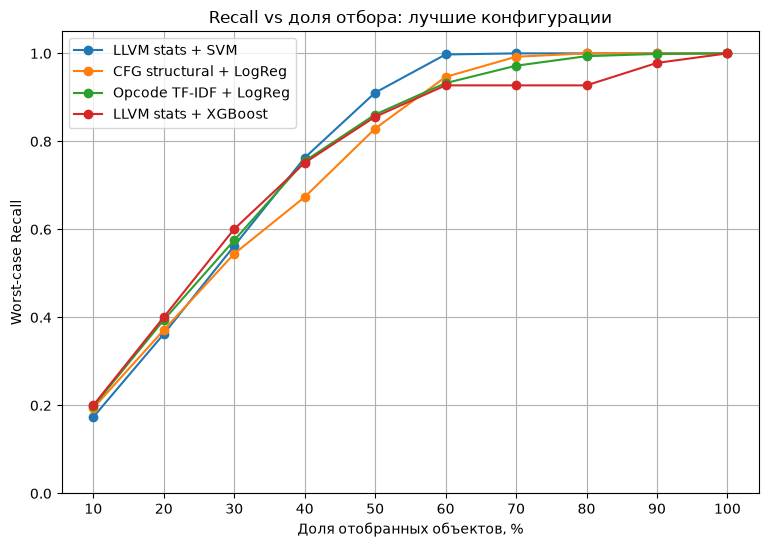

In [190]:
plt.figure(figsize=(9, 6))

for _, config in top4.iterrows():

    rep = config["representation"]
    model = config["model"]

    part = ranking_all_summary[
        (ranking_all_summary["representation"] == rep)
        &
        (ranking_all_summary["model"] == model)
    ]

    plt.plot(
        part["fraction"] * 100,
        part["worst_recall"],
        marker="o",
        label=f"{rep} + {model}",
    )

plt.xlabel("Доля отобранных объектов, %")
plt.ylabel("Worst-case Recall")
plt.title("Recall vs доля отбора: лучшие конфигурации")
plt.xticks(range(10, 101, 10))
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()

plt.show()

In [191]:
ranking_all_df.to_excel(
    RESULTS_DIR / "ranking_all_models.xlsx",
    index=False,
)

ranking_all_summary.to_excel(
    RESULTS_DIR / "ranking_all_models_summary.xlsx",
    index=False,
)

compare_60_80.to_excel(
    RESULTS_DIR / "ranking_60_70_80.xlsx"
)

threshold_df.to_excel(
    RESULTS_DIR / "ranking_thresholds.xlsx",
    index=False,
)

model_choice.to_excel(
    RESULTS_DIR / "model_choice.xlsx",
    index=False,
)

/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


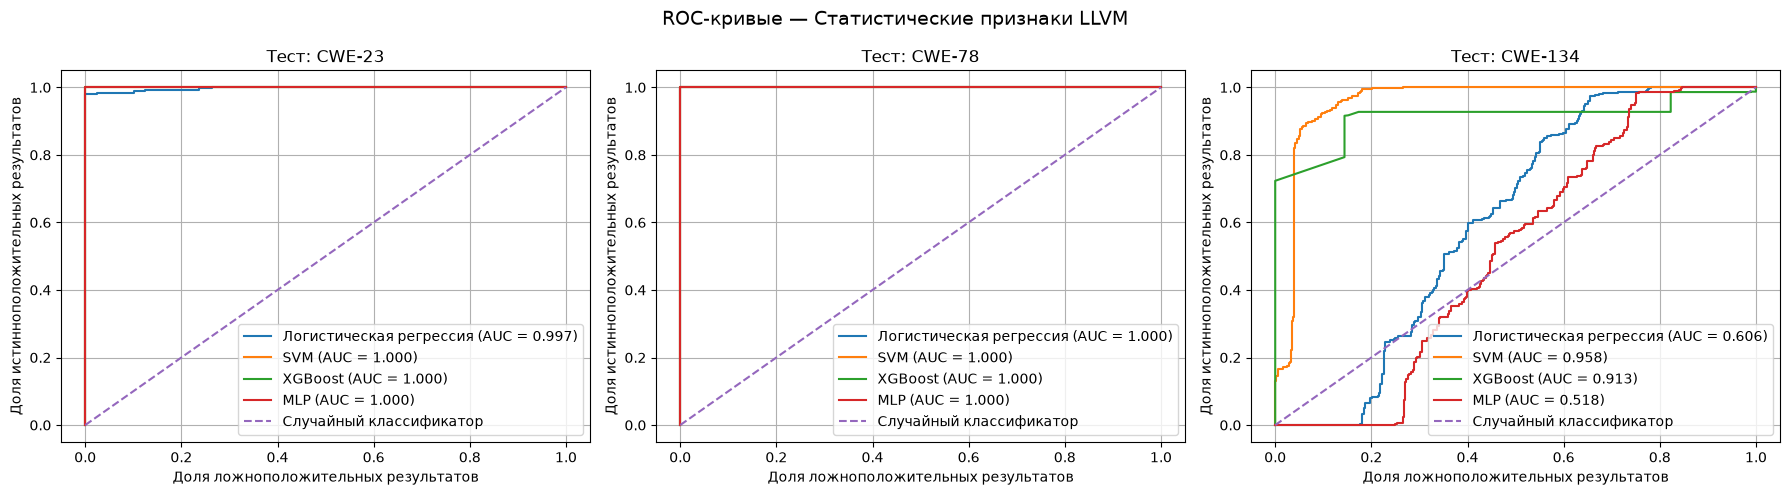

/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


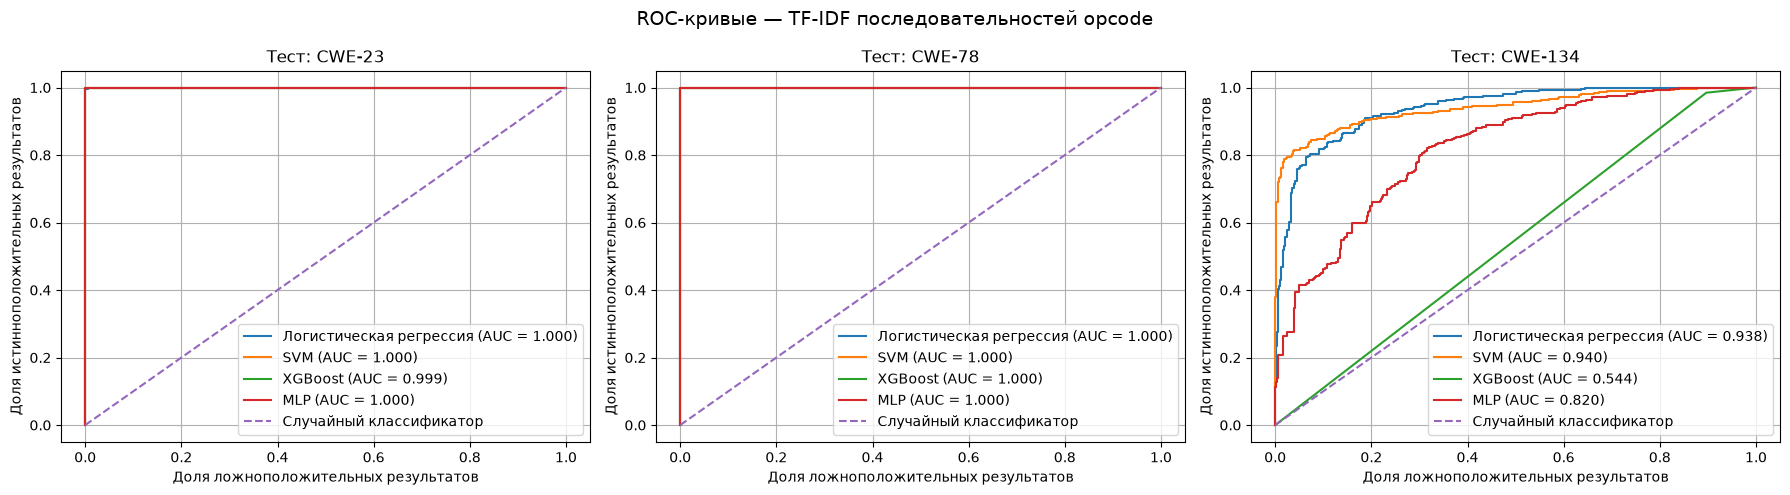

/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


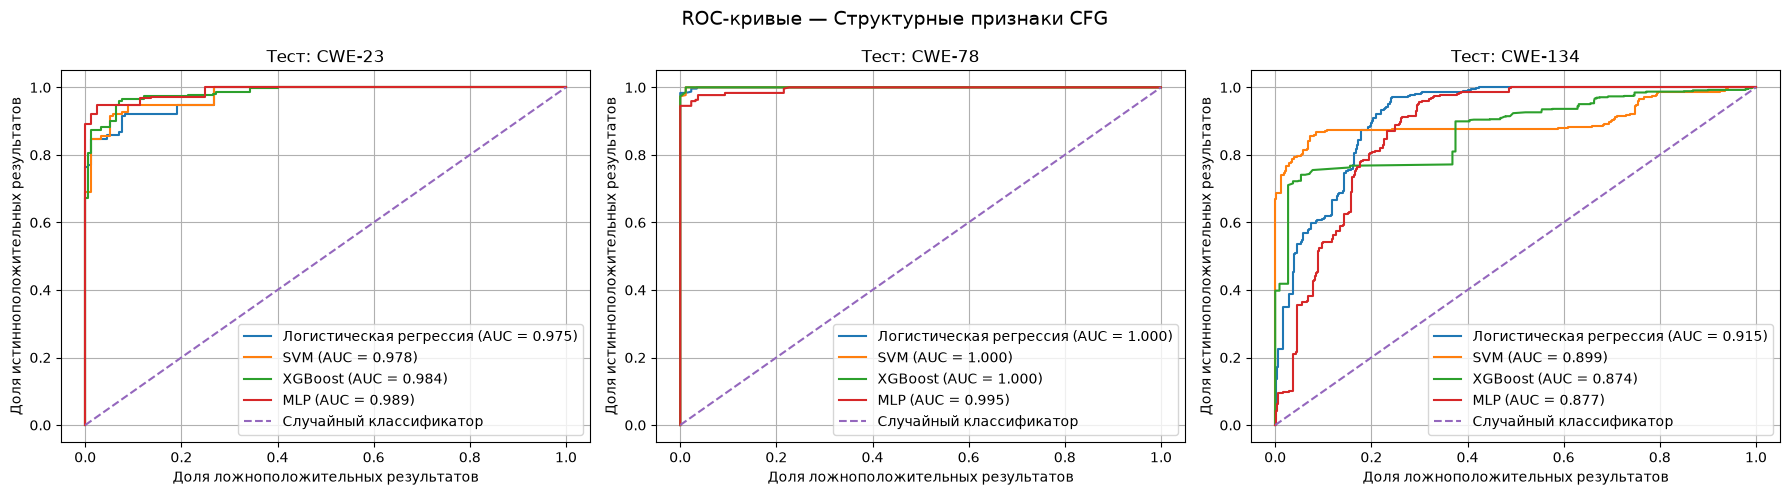

In [192]:
model_names_ru = {
    "LogReg": "Логистическая регрессия",
    "SVM": "SVM",
    "XGBoost": "XGBoost",
    "MLP": "MLP",
}

representation_names_ru = {
    "LLVM stats": "Статистические признаки LLVM",
    "Opcode TF-IDF": "TF-IDF последовательностей opcode",
    "CFG structural": "Структурные признаки CFG",
}

cwe_names_ru = {
    "cwe23": "CWE-23",
    "cwe78": "CWE-78",
    "cwe134": "CWE-134",
}

for representation in [
    "LLVM stats",
    "Opcode TF-IDF",
    "CFG structural"
]:

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, held_out_cwe in zip(
        axes,
        ["cwe23", "cwe78", "cwe134"]
    ):

        train_mask = df["cwe"] != held_out_cwe
        test_mask = df["cwe"] == held_out_cwe

        y_train_roc = df.loc[
            train_mask,
            "target"
        ].to_numpy()

        y_test_roc = df.loc[
            test_mask,
            "target"
        ].to_numpy()

        if representation == "LLVM stats":

            X_train_roc = features_df.loc[train_mask]
            X_test_roc = features_df.loc[test_mask]

        elif representation == "CFG structural":

            X_train_roc = cfg_df.loc[train_mask]
            X_test_roc = cfg_df.loc[test_mask]

        else:

            train_indices = df.index[train_mask]
            test_indices = df.index[test_mask]

            train_texts = [
                opcode_texts[i]
                for i in train_indices
            ]

            test_texts = [
                opcode_texts[i]
                for i in test_indices
            ]

            tfidf_roc = TfidfVectorizer(
                tokenizer=str.split,
                preprocessor=None,
                token_pattern=None,
                ngram_range=(1, 2),
                min_df=2,
            )

            X_train_roc = tfidf_roc.fit_transform(
                train_texts
            )

            X_test_roc = tfidf_roc.transform(
                test_texts
            )

        models = make_ranking_models()

        for model_name, model in models.items():

            model.fit(
                X_train_roc,
                y_train_roc
            )

            scores = get_ranking_scores(
                model,
                X_test_roc
            )

            fpr, tpr, _ = roc_curve(
                y_test_roc,
                scores
            )

            auc = roc_auc_score(
                y_test_roc,
                scores
            )

            ax.plot(
                fpr,
                tpr,
                label=(
                    f"{model_names_ru[model_name]} "
                    f"(AUC = {auc:.3f})"
                )
            )

        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            label="Случайный классификатор"
        )

        ax.set_title(
            f"Тест: {cwe_names_ru[held_out_cwe]}"
        )

        ax.set_xlabel(
            "Доля ложноположительных результатов"
        )

        ax.set_ylabel(
            "Доля истинноположительных результатов"
        )

        ax.grid()
        ax.legend()

    fig.suptitle(
        "ROC-кривые — "
        + representation_names_ru[representation],
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/timur/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


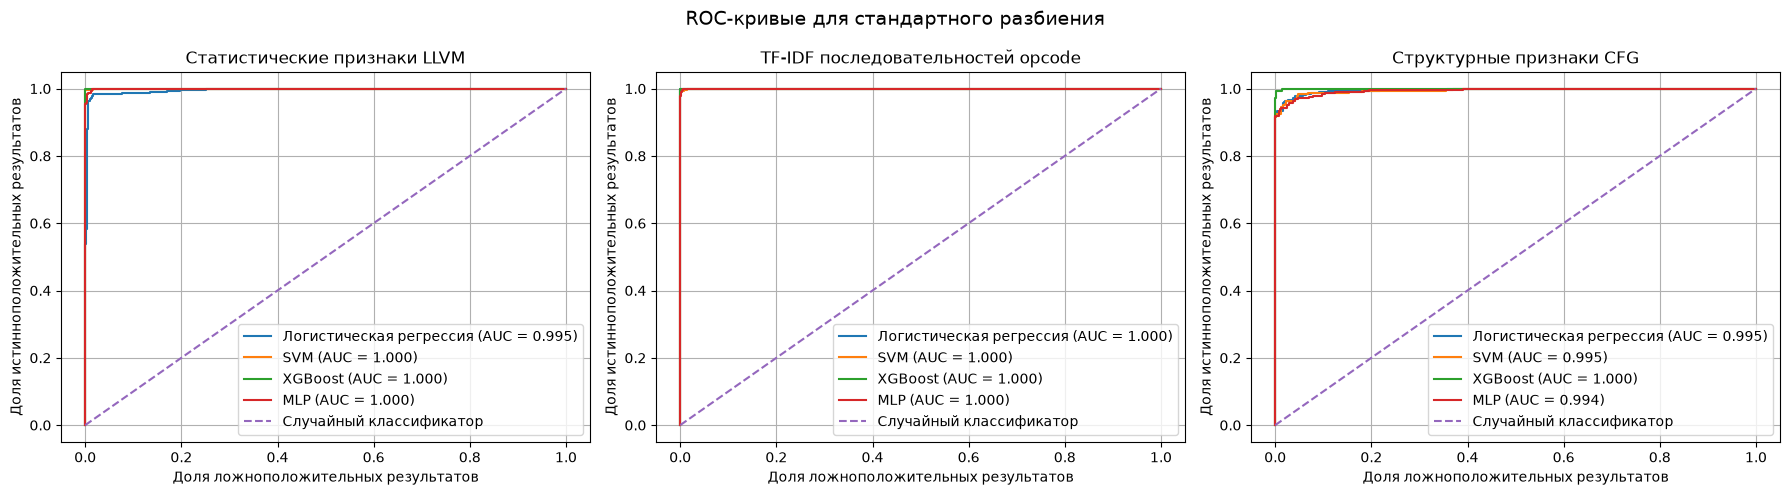

In [193]:
model_names_ru = {
    "LogReg": "Логистическая регрессия",
    "SVM": "SVM",
    "XGBoost": "XGBoost",
    "MLP": "MLP",
}

representation_names_ru = {
    "LLVM stats": "Статистические признаки LLVM",
    "Opcode TF-IDF": "TF-IDF последовательностей opcode",
    "CFG structural": "Структурные признаки CFG",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, representation in zip(
    axes,
    ["LLVM stats", "Opcode TF-IDF", "CFG structural"]
):

    y_train_roc = df.iloc[train_idx]["target"].to_numpy()
    y_test_roc = df.iloc[test_idx]["target"].to_numpy()

    if representation == "LLVM stats":

        X_train_roc = features_df.iloc[train_idx]
        X_test_roc = features_df.iloc[test_idx]

    elif representation == "CFG structural":

        X_train_roc = cfg_df.iloc[train_idx]
        X_test_roc = cfg_df.iloc[test_idx]

    else:

        train_texts = [
            opcode_texts[i]
            for i in train_idx
        ]

        test_texts = [
            opcode_texts[i]
            for i in test_idx
        ]

        tfidf_roc = TfidfVectorizer(
            tokenizer=str.split,
            preprocessor=None,
            token_pattern=None,
            ngram_range=(1, 2),
            min_df=2,
        )

        X_train_roc = tfidf_roc.fit_transform(
            train_texts
        )

        X_test_roc = tfidf_roc.transform(
            test_texts
        )

    models = make_ranking_models()

    for model_name, model in models.items():

        model.fit(
            X_train_roc,
            y_train_roc
        )

        scores = get_ranking_scores(
            model,
            X_test_roc
        )

        fpr, tpr, _ = roc_curve(
            y_test_roc,
            scores
        )

        auc = roc_auc_score(
            y_test_roc,
            scores
        )

        ax.plot(
            fpr,
            tpr,
            label=(
                f"{model_names_ru[model_name]} "
                f"(AUC = {auc:.3f})"
            )
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Случайный классификатор"
    )

    ax.set_title(
        representation_names_ru[representation]
    )

    ax.set_xlabel(
        "Доля ложноположительных результатов"
    )

    ax.set_ylabel(
        "Доля истинноположительных результатов"
    )

    ax.grid()
    ax.legend()

fig.suptitle(
    "ROC-кривые для стандартного разбиения",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Замеряю скорости

In [194]:
test_paths = df.iloc[test_idx]["path"].tolist()

times = []

for _ in range(5):
    start = time.perf_counter()

    rows = [
        extract_llvm_stats(path)
        for path in test_paths
    ]

    elapsed = time.perf_counter() - start
    times.append(elapsed / len(test_paths) * 1000)
llvm_mean = np.mean(times[1:])
llvm_std = np.std(times[1:])
llvm_times = times[1:]
print("LLVM stats, мс/образец:", np.mean(times))
print("std:", np.std(times))

LLVM stats, мс/образец: 0.09316435966084216
std: 0.0005646391821631732


In [195]:
times = []

for _ in range(5):
    start = time.perf_counter()

    rows = [
        extract_cfg_features(path)
        for path in test_paths
    ]

    elapsed = time.perf_counter() - start
    times.append(elapsed / len(test_paths) * 1000)
cfg_mean = np.mean(times[1:])
cfg_std = np.std(times[1:])
cfg_times = times[1:]
print("CFG structural, мс/образец:", np.mean(times))
print("std:", np.std(times))

CFG structural, мс/образец: 0.07581113354572848
std: 0.0015638854975420008


In [196]:
train_paths = df.iloc[train_idx]["path"].tolist()

train_opcode_texts = [
    " ".join(extract_opcode_sequence(path))
    for path in train_paths
]

tfidf_time = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    ngram_range=(1, 2),
    min_df=2,
)

tfidf_time.fit(train_opcode_texts)

,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<method 'spli...'str' objects>
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",None
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'


In [197]:
times = []

for _ in range(5):

    start = time.perf_counter()

    test_opcode_texts = [
        " ".join(extract_opcode_sequence(path))
        for path in test_paths
    ]

    X_test_time = tfidf_time.transform(
        test_opcode_texts
    )

    elapsed = time.perf_counter() - start

    times.append(
        elapsed / len(test_paths) * 1000
    )
tfidf_mean = np.mean(times[1:])
tfidf_std = np.std(times[1:])
tfidf_times = times[1:]
print("Opcode TF-IDF, мс/образец:", np.mean(times))
print("std:", np.std(times))

Opcode TF-IDF, мс/образец: 0.07110266050927176
std: 0.0003004824366180281


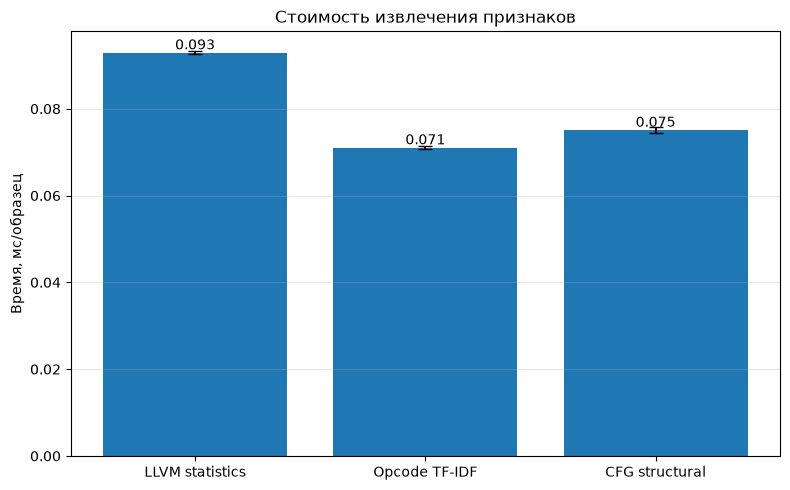

In [198]:
names = [
    "LLVM statistics",
    "Opcode TF-IDF",
    "CFG structural",
]

means = [
    llvm_mean,
    tfidf_mean,
    cfg_mean,
]

stds = [
    llvm_std,
    tfidf_std,
    cfg_std,
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    names,
    means,
    yerr=stds,
    capsize=5,
)

ax.set_ylabel("Время, мс/образец")
ax.set_title("Стоимость извлечения признаков")
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

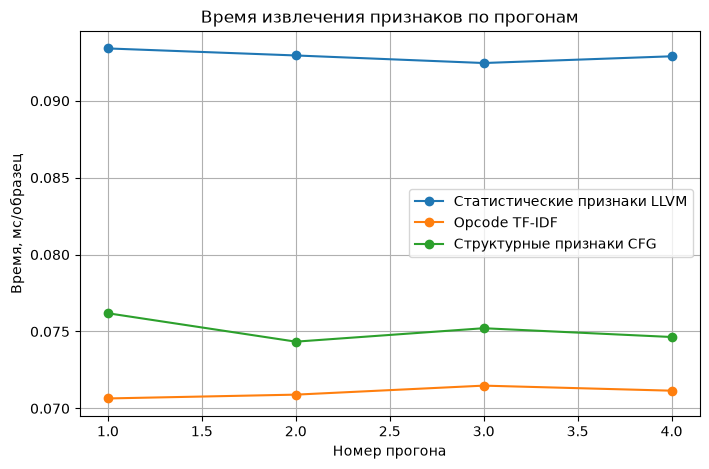

In [199]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(llvm_times) + 1),
    llvm_times,
    marker="o",
    label="Статистические признаки LLVM"
)

plt.plot(
    range(1, len(tfidf_times) + 1),
    tfidf_times,
    marker="o",
    label="Opcode TF-IDF"
)

plt.plot(
    range(1, len(cfg_times) + 1),
    cfg_times,
    marker="o",
    label="Структурные признаки CFG"
)

plt.xlabel("Номер прогона")
plt.ylabel("Время, мс/образец")
plt.title("Время извлечения признаков по прогонам")

plt.grid()
plt.legend()

plt.show()

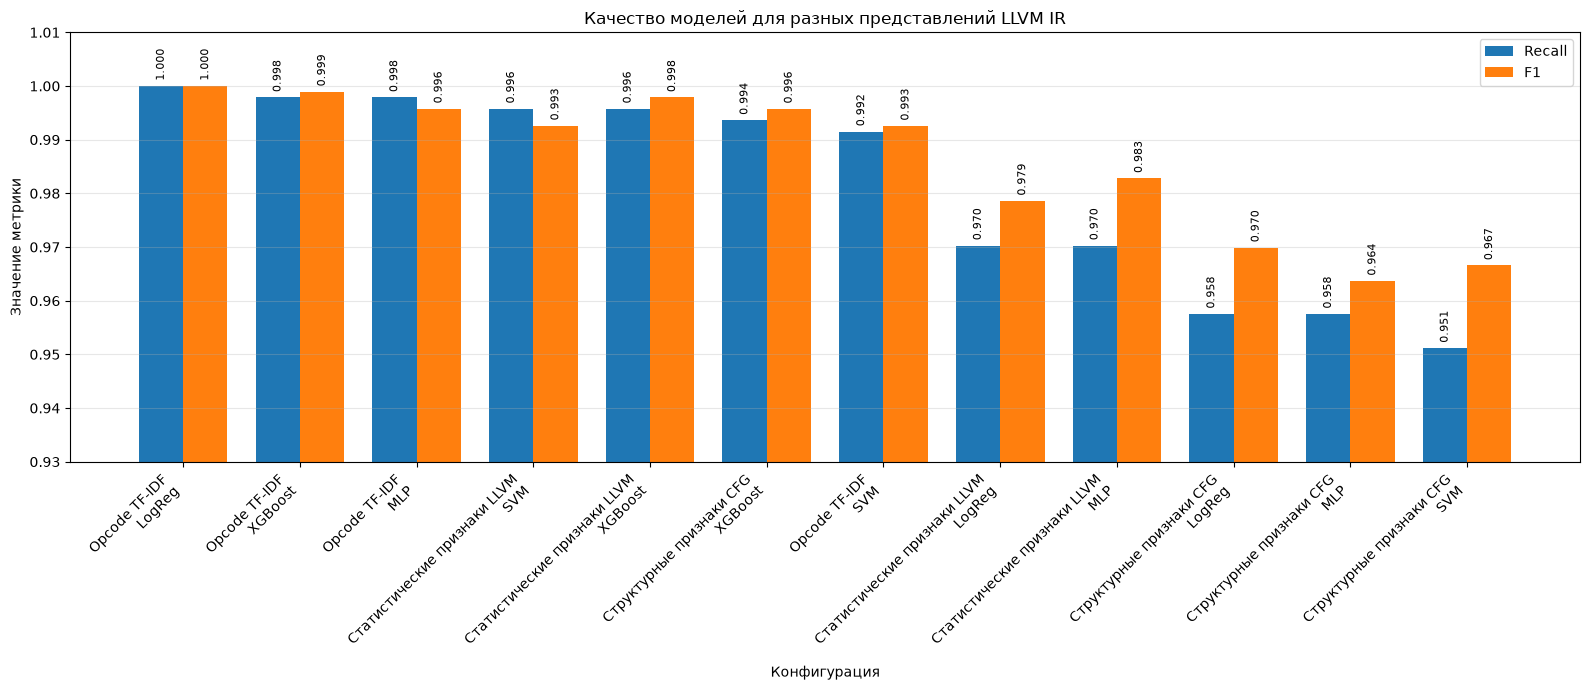

In [200]:

# копия таблицы, чтобы не портить исходную
plot_df = benchmark_df.copy()

# русские подписи представлений
repr_map = {
    "LLVM stats": "Статистические признаки LLVM",
    "Opcode TF-IDF": "Opcode TF-IDF",
    "CFG structural": "Структурные признаки CFG",
}

# если модель у тебя называется SVM_RBF, замени на SVM
model_map = {
    "LogReg": "LogReg",
    "SVM": "SVM",
    "SVM_RBF": "SVM",
    "XGBoost": "XGBoost",
    "MLP": "MLP",
}

plot_df["representation_ru"] = plot_df["representation"].map(repr_map).fillna(plot_df["representation"])
plot_df["model_ru"] = plot_df["model"].map(model_map).fillna(plot_df["model"])

# подпись конфигурации на оси X
plot_df["config"] = (
    plot_df["representation_ru"] + "\n" + plot_df["model_ru"]
)

# можно отсортировать по Recall
plot_df = plot_df.sort_values("recall", ascending=False).reset_index(drop=True)

x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(16, 7))

bars1 = ax.bar(
    x - width/2,
    plot_df["recall"],
    width,
    label="Recall"
)

bars2 = ax.bar(
    x + width/2,
    plot_df["f1"],
    width,
    label="F1"
)

ax.set_title("Качество моделей для разных представлений LLVM IR")
ax.set_ylabel("Значение метрики")
ax.set_xlabel("Конфигурация")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["config"], rotation=45, ha="right")
ax.set_ylim(0.93, 1.01)   # можешь убрать, если хочешь полную шкалу от 0
ax.grid(axis="y", alpha=0.3)
ax.legend()

# подписи значений над столбцами
for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.001,
            f"{h:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

plt.tight_layout()
plt.show()

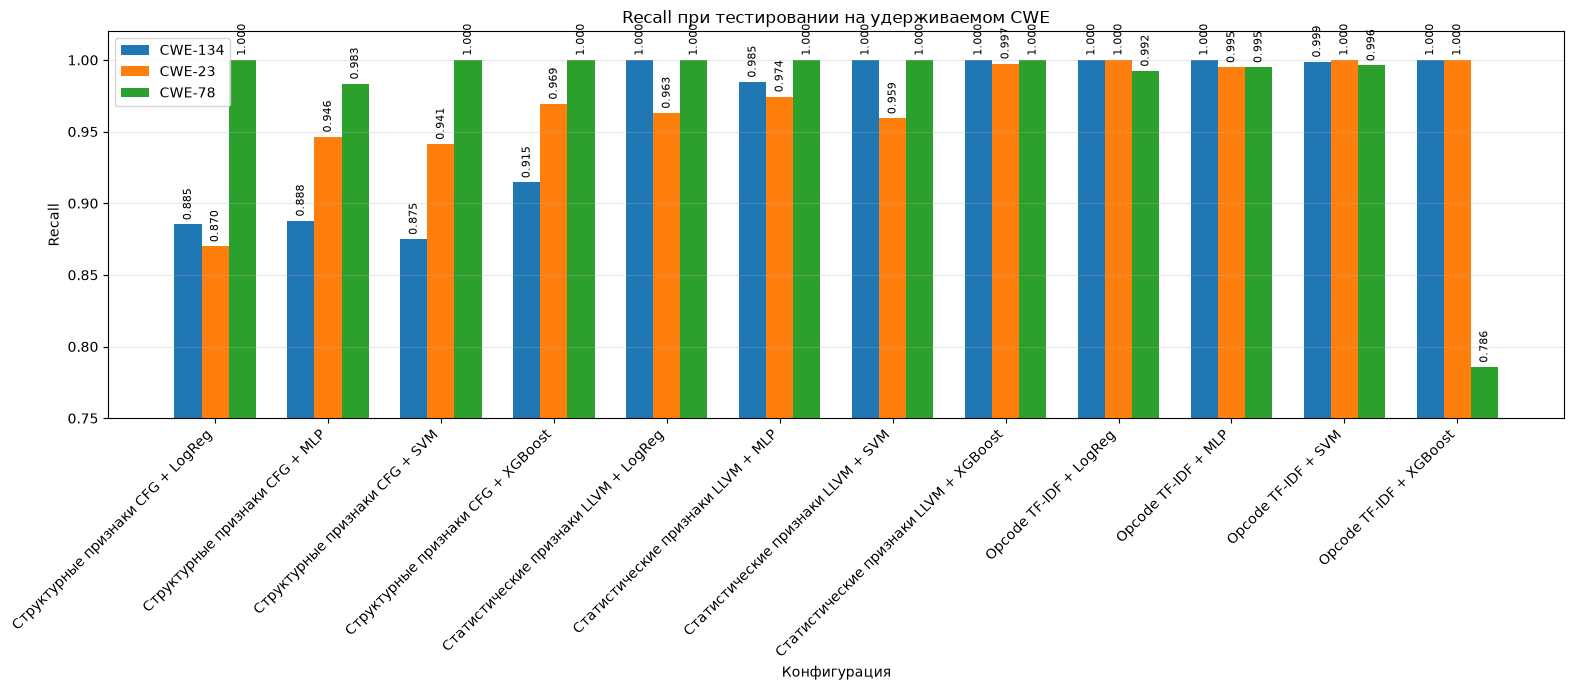

In [201]:

plot_df = loo_recall_matrix.copy().reset_index()



model_map = {
    "LogReg": "LogReg",
    "SVM": "SVM",
    "SVM_RBF": "SVM",
    "XGBoost": "XGBoost",
    "MLP": "MLP",
}

plot_df["repr_short"] = plot_df["representation"].map(repr_map).fillna(plot_df["representation"])
plot_df["model_short"] = plot_df["model"].map(model_map).fillna(plot_df["model"])

plot_df["config"] = plot_df["repr_short"] + " + " + plot_df["model_short"]

# порядок столбцов
cwe_cols = ["cwe134", "cwe23", "cwe78"]

# если хочешь русские подписи CWE в легенде
legend_labels = {
    "cwe134": "CWE-134",
    "cwe23": "CWE-23",
    "cwe78": "CWE-78",
}

x = np.arange(len(plot_df))
width = 0.24

fig, ax = plt.subplots(figsize=(16, 7))

bars1 = ax.bar(
    x - width,
    plot_df["cwe134"],
    width,
    label="CWE-134"
)

bars2 = ax.bar(
    x,
    plot_df["cwe23"],
    width,
    label="CWE-23"
)

bars3 = ax.bar(
    x + width,
    plot_df["cwe78"],
    width,
    label="CWE-78"
)

ax.set_title("Recall при тестировании на удерживаемом CWE")
ax.set_ylabel("Recall")
ax.set_xlabel("Конфигурация")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["config"], rotation=45, ha="right")
ax.set_ylim(0.75, 1.02)
ax.grid(axis="y", alpha=0.3)
ax.legend()

# подписи значений над столбцами
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.003,
            f"{h:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

plt.tight_layout()
plt.show()

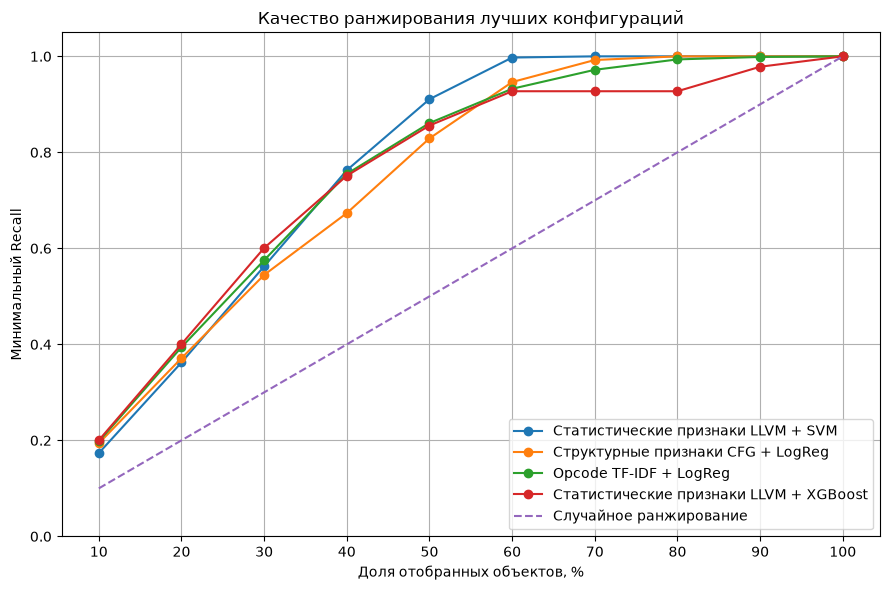

In [202]:
repr_map = {
    "LLVM stats": "Статистические признаки LLVM",
    "Opcode TF-IDF": "Opcode TF-IDF",
    "CFG structural": "Структурные признаки CFG",
}

model_map = {
    "LogReg": "LogReg",
    "SVM": "SVM",
    "XGBoost": "XGBoost",
    "MLP": "MLP",
}

top4 = (
    compare_60_80
    .reset_index()
    .head(4)[["representation", "model"]]
)

plt.figure(figsize=(9, 6))

for _, config in top4.iterrows():

    rep = config["representation"]
    model = config["model"]

    part = ranking_all_summary[
        (ranking_all_summary["representation"] == rep) &
        (ranking_all_summary["model"] == model)
    ].sort_values("fraction")

    plt.plot(
        part["fraction"] * 100,
        part["worst_recall"],
        marker="o",
        label=f"{repr_map[rep]} + {model_map[model]}"
    )

# случайное ранжирование:
# если выбираем x% объектов случайно,
# ожидаемый Recall примерно x%
plt.plot(
    [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    linestyle="--",
    label="Случайное ранжирование"
)

plt.xlabel("Доля отобранных объектов, %")
plt.ylabel("Минимальный Recall")
plt.title("Качество ранжирования лучших конфигураций")
plt.xticks(range(10, 101, 10))
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()